In [2]:
import kagglehub

path = kagglehub.dataset_download("awsaf49/isic-2017")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/awsaf49/isic-2017


In [3]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image
import matplotlib.pyplot as plt

In [4]:
import os

for root, dirs, files in os.walk(path):
    print(root, "->", len(files), "files")

/kaggle/input/datasets/awsaf49/isic-2017 -> 4 files
/kaggle/input/datasets/awsaf49/isic-2017/images -> 0 files
/kaggle/input/datasets/awsaf49/isic-2017/images/images -> 4001 files
/kaggle/input/datasets/awsaf49/isic-2017/masks -> 0 files
/kaggle/input/datasets/awsaf49/isic-2017/masks/masks -> 2000 files


In [5]:
import os

base = "/kaggle/input/datasets/awsaf49/isic-2017"

for item in os.listdir(base):
    full_path = os.path.join(base, item)
    print(item, "->", os.path.getsize(full_path) / (1024**2) if os.path.isfile(full_path) else "FOLDER")

images -> FOLDER
train_data.csv -> 0.23885536193847656
test_data.csv -> 0.028011322021484375
data.csv -> 0.2668266296386719
masks -> FOLDER
ISIC_2017_GroundTruth.csv -> 0.05893993377685547


In [6]:
import os

base = "/kaggle/input/datasets/awsaf49/isic-2017"

print("Images:", len(os.listdir(os.path.join(base, "images"))))
print("Masks :", len(os.listdir(os.path.join(base, "masks"))))

print("\nSample images:")
print(os.listdir(os.path.join(base, "images"))[:5])

print("\nSample masks:")
print(os.listdir(os.path.join(base, "masks"))[:5])

Images: 1
Masks : 1

Sample images:
['images']

Sample masks:
['masks']


In [7]:
import os

base = "/kaggle/input/datasets/awsaf49/isic-2017"

for root, dirs, files in os.walk(base):
    print(root, "->", len(files), "files")

/kaggle/input/datasets/awsaf49/isic-2017 -> 4 files
/kaggle/input/datasets/awsaf49/isic-2017/images -> 0 files
/kaggle/input/datasets/awsaf49/isic-2017/images/images -> 4001 files
/kaggle/input/datasets/awsaf49/isic-2017/masks -> 0 files
/kaggle/input/datasets/awsaf49/isic-2017/masks/masks -> 2000 files


In [8]:
import os

image_dir = "/kaggle/input/datasets/awsaf49/isic-2017/images/images"
mask_dir = "/kaggle/input/datasets/awsaf49/isic-2017/masks/masks"

print("Images:")
print(os.listdir(image_dir)[:10])

print("\nMasks:")
print(os.listdir(mask_dir)[:10])

Images:
['ISIC_0012706.jpg', 'ISIC_0010192.jpg', 'ISIC_0000466_superpixels.png', 'ISIC_0014707_superpixels.png', 'ISIC_0010017.jpg', 'ISIC_0013000.jpg', 'ISIC_0010059_superpixels.png', 'ISIC_0013166.jpg', 'ISIC_0013433_superpixels.png', 'ISIC_0003308.jpg']

Masks:
['ISIC_0000505_segmentation.png', 'ISIC_0000057_segmentation.png', 'ISIC_0000467_segmentation.png', 'ISIC_0012880_segmentation.png', 'ISIC_0005555_segmentation.png', 'ISIC_0012379_segmentation.png', 'ISIC_0000226_segmentation.png', 'ISIC_0000082_segmentation.png', 'ISIC_0013579_segmentation.png', 'ISIC_0009987_segmentation.png']


In [9]:
import pandas as pd

base = "/kaggle/input/datasets/awsaf49/isic-2017"

train_df = pd.read_csv(os.path.join(base, "train_data.csv"))

print(train_df.head())
print(train_df.columns)
print(train_df.shape)

       image_id                                         image_path  \
0  ISIC_0000002  /kaggle/input/isic-2017/images/images/ISIC_000...   
1  ISIC_0000004  /kaggle/input/isic-2017/images/images/ISIC_000...   
2  ISIC_0000013  /kaggle/input/isic-2017/images/images/ISIC_000...   
3  ISIC_0000022  /kaggle/input/isic-2017/images/images/ISIC_000...   
4  ISIC_0000026  /kaggle/input/isic-2017/images/images/ISIC_000...   

                                           mask_path class  label  
0  /kaggle/input/isic-2017/masks/masks/ISIC_00000...   mel      0  
1  /kaggle/input/isic-2017/masks/masks/ISIC_00000...   mel      0  
2  /kaggle/input/isic-2017/masks/masks/ISIC_00000...   mel      0  
3  /kaggle/input/isic-2017/masks/masks/ISIC_00000...   mel      0  
4  /kaggle/input/isic-2017/masks/masks/ISIC_00000...   mel      0  
Index(['image_id', 'image_path', 'mask_path', 'class', 'label'], dtype='object')
(1790, 5)


In [10]:
import pandas as pd

base = "/kaggle/input/datasets/awsaf49/isic-2017"

df = pd.read_csv(base + "/train_data.csv")

print("Total pairs:", len(df))
print(df[["image_id", "image_path", "mask_path"]].head())
print("\nMissing images:", df["image_path"].isna().sum())
print("Missing masks:", df["mask_path"].isna().sum())

Total pairs: 1790
       image_id                                         image_path  \
0  ISIC_0000002  /kaggle/input/isic-2017/images/images/ISIC_000...   
1  ISIC_0000004  /kaggle/input/isic-2017/images/images/ISIC_000...   
2  ISIC_0000013  /kaggle/input/isic-2017/images/images/ISIC_000...   
3  ISIC_0000022  /kaggle/input/isic-2017/images/images/ISIC_000...   
4  ISIC_0000026  /kaggle/input/isic-2017/images/images/ISIC_000...   

                                           mask_path  
0  /kaggle/input/isic-2017/masks/masks/ISIC_00000...  
1  /kaggle/input/isic-2017/masks/masks/ISIC_00000...  
2  /kaggle/input/isic-2017/masks/masks/ISIC_00000...  
3  /kaggle/input/isic-2017/masks/masks/ISIC_00000...  
4  /kaggle/input/isic-2017/masks/masks/ISIC_00000...  

Missing images: 0
Missing masks: 0


In [11]:
from PIL import Image
import os

row = df.iloc[0]

image_path = row["image_path"].replace(
    "/kaggle/input/isic-2017",
    base
)

mask_path = row["mask_path"].replace(
    "/kaggle/input/isic-2017",
    base
)

image = Image.open(image_path)
mask = Image.open(mask_path)

print("Image:", image.size, image.mode)
print("Mask :", mask.size, mask.mode)

Image: (1022, 767) RGB
Mask : (1022, 767) L


In [12]:
IMAGE_DIR = "/kaggle/input/datasets/awsaf49/isic-2017/images/images"
MASK_DIR = "/kaggle/input/datasets/awsaf49/isic-2017/masks/masks"

In [13]:
import os
from collections import Counter

IMAGE_DIR = "/kaggle/input/datasets/awsaf49/isic-2017/images/images"
MASK_DIR = "/kaggle/input/datasets/awsaf49/isic-2017/masks/masks"

image_types = Counter(
    os.path.splitext(f)[1].lower()
    for f in os.listdir(IMAGE_DIR)
    if os.path.isfile(os.path.join(IMAGE_DIR, f))
)

mask_types = Counter(
    os.path.splitext(f)[1].lower()
    for f in os.listdir(MASK_DIR)
    if os.path.isfile(os.path.join(MASK_DIR, f))
)

print("Image file types:")
for ext, count in image_types.items():
    print(ext, ":", count)

print("\nMask file types:")
for ext, count in mask_types.items():
    print(ext, ":", count)

Image file types:
.jpg : 2000
.png : 2000
.csv : 1

Mask file types:
.png : 2000


In [14]:
import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset
from PIL import Image

# =========================================================
# 1. Paths
# =========================================================

BASE = "/kaggle/input/datasets/awsaf49/isic-2017"

CSV_PATH = os.path.join(BASE, "train_data.csv")

# Read CSV
df = pd.read_csv(CSV_PATH)

print("Total pairs:", len(df))


# =========================================================
# 2. Dataset
# =========================================================

class ISICDataset(Dataset):

    def __init__(self, dataframe, image_size=(256, 256)):

        self.df = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # ---------------------------------------------
        # Correct Kaggle paths
        # ---------------------------------------------

        image_path = row["image_path"].replace(
            "/kaggle/input/isic-2017",
            BASE
        )

        mask_path = row["mask_path"].replace(
            "/kaggle/input/isic-2017",
            BASE
        )

        # ---------------------------------------------
        # Load image
        # ---------------------------------------------

        image = Image.open(image_path).convert("RGB")

        # ---------------------------------------------
        # Load mask
        # ---------------------------------------------

        mask = Image.open(mask_path).convert("L")

        # ---------------------------------------------
        # Resize
        # ---------------------------------------------

        image = image.resize(
            self.image_size,
            Image.Resampling.BILINEAR
        )

        # IMPORTANT:
        # Use NEAREST for segmentation masks
        mask = mask.resize(
            self.image_size,
            Image.Resampling.NEAREST
        )

        # ---------------------------------------------
        # Convert image to NumPy
        # ---------------------------------------------

        image = np.array(image, dtype=np.float32)

        # Normalize image [0,255] → [0,1]

        image = image / 255.0

        # ---------------------------------------------
        # Convert mask to NumPy
        # ---------------------------------------------

        mask = np.array(mask, dtype=np.float32)

        # Normalize mask

        mask = mask / 255.0

        # Binary mask

        mask = (mask > 0.5).astype(np.float32)

        # ---------------------------------------------
        # H,W,C → C,H,W
        # ---------------------------------------------

        image = torch.from_numpy(image).permute(2, 0, 1)

        # H,W → 1,H,W

        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask

Total pairs: 1790


In [15]:
dataset = ISICDataset(df)

print("Dataset size:", len(dataset))

image, mask = dataset[0]

print("Image shape:", image.shape)
print("Mask shape :", mask.shape)

print("Image min:", image.min().item())
print("Image max:", image.max().item())

print("Mask values:", torch.unique(mask))

Dataset size: 1790
Image shape: torch.Size([3, 256, 256])
Mask shape : torch.Size([1, 256, 256])
Image min: 0.0117647061124444
Image max: 1.0
Mask values: tensor([0., 1.])


In [16]:
import pandas as pd
import os

BASE = "/kaggle/input/datasets/awsaf49/isic-2017"

train_df = pd.read_csv(os.path.join(BASE, "train_data.csv"))
test_df = pd.read_csv(os.path.join(BASE, "test_data.csv"))
data_df = pd.read_csv(os.path.join(BASE, "data.csv"))

print("Train:", len(train_df))
print("Test :", len(test_df))
print("Data :", len(data_df))

print("\nTrain columns:")
print(train_df.columns)

print("\nTest columns:")
print(test_df.columns)

Train: 1790
Test : 210
Data : 2000

Train columns:
Index(['image_id', 'image_path', 'mask_path', 'class', 'label'], dtype='object')

Test columns:
Index(['image_id', 'image_path', 'mask_path', 'class', 'label'], dtype='object')


In [17]:
import pandas as pd
from sklearn.model_selection import train_test_split
import os

BASE = "/kaggle/input/datasets/awsaf49/isic-2017"

# Load official train and test splits
train_df = pd.read_csv(os.path.join(BASE, "train_data.csv"))
test_df = pd.read_csv(os.path.join(BASE, "test_data.csv"))

# Split the 1790 training samples
train_df, val_df = train_test_split(
    train_df,
    test_size=0.10,
    random_state=42,
    stratify=train_df["label"]
)

print("Training samples  :", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples      :", len(test_df))

Training samples  : 1611
Validation samples: 179
Test samples      : 210


In [18]:
from torch.utils.data import DataLoader

train_dataset = ISICDataset(train_df)
val_dataset = ISICDataset(val_df)
test_dataset = ISICDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training samples: 1611
Validation samples: 179
Test samples: 210
Training batches: 403
Validation batches: 45
Test batches: 53


In [19]:
images, masks = next(iter(train_loader))

print("Images:", images.shape)
print("Masks :", masks.shape)

Images: torch.Size([4, 3, 256, 256])
Masks : torch.Size([4, 1, 256, 256])


In [20]:
final_conv = nn.Conv2d(
    in_channels=16,
    out_channels=1,
    kernel_size=1
)

print("Final convolution created")

Final convolution created


In [21]:
class ISICDataset(Dataset):

    def __init__(self, dataframe, image_size=(256, 256)):

        self.df = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        # Correct Kaggle path
        image_path = row["image_path"].replace(
            "/kaggle/input/isic-2017",
            BASE
        )

        mask_path = row["mask_path"].replace(
            "/kaggle/input/isic-2017",
            BASE
        )

        # Load
        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        # Resize
        image = image.resize(
            self.image_size,
            Image.Resampling.BILINEAR
        )

        mask = mask.resize(
            self.image_size,
            Image.Resampling.NEAREST
        )

        # Convert to tensor and normalize image to [0,1]
        image = transforms.ToTensor()(image)

        # Convert mask to tensor
        mask = transforms.ToTensor()(mask)

        # Binary mask
        mask = (mask > 0.5).float()

        return image, mask

In [22]:
train_dataset = ISICDataset(train_df)
val_dataset = ISICDataset(val_df)
test_dataset = ISICDataset(test_df)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 1611
Validation: 179
Test: 210


In [23]:
class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

In [24]:
class EncoderBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = DoubleConv(
            in_channels,
            out_channels
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

    def forward(self, x):

        features = self.conv(x)

        pooled = self.pool(features)

        return features, pooled

In [25]:
encoder1 = EncoderBlock(3, 64)
encoder2 = EncoderBlock(64, 128)
encoder3 = EncoderBlock(128, 256)
encoder4 = EncoderBlock(256, 512)

In [26]:

# Get one batch from the training loader
images, masks = next(iter(train_loader))

print("Input:", images.shape)

# Pass through encoder blocks
features1, pooled1 = encoder1(images)

features2, pooled2 = encoder2(pooled1)

features3, pooled3 = encoder3(pooled2)

features4, pooled4 = encoder4(pooled3)

# Print shapes
print("Features1:", features1.shape)
print("Pooled1  :", pooled1.shape)

print("Features2:", features2.shape)
print("Pooled2  :", pooled2.shape)

print("Features3:", features3.shape)
print("Pooled3  :", pooled3.shape)

print("Features4:", features4.shape)
print("Pooled4  :", pooled4.shape)

Input: torch.Size([4, 3, 256, 256])
Features1: torch.Size([4, 64, 256, 256])
Pooled1  : torch.Size([4, 64, 128, 128])
Features2: torch.Size([4, 128, 128, 128])
Pooled2  : torch.Size([4, 128, 64, 64])
Features3: torch.Size([4, 256, 64, 64])
Pooled3  : torch.Size([4, 256, 32, 32])
Features4: torch.Size([4, 512, 32, 32])
Pooled4  : torch.Size([4, 512, 16, 16])


In [27]:
bottleneck = DoubleConv(512, 1024)

bottleneck_output = bottleneck(pooled4)

print("Bottleneck shape:", bottleneck_output.shape)

Bottleneck shape: torch.Size([4, 1024, 16, 16])


In [28]:
class ChannelAttention(nn.Module):

    def __init__(self, channels, reduction=16):
        super().__init__()

        hidden = max(channels // reduction, 1)

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(channels, hidden, kernel_size=1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_attention = self.fc(
            self.avg_pool(x)
        )

        max_attention = self.fc(
            self.max_pool(x)
        )

        attention = avg_attention + max_attention

        attention = self.sigmoid(attention)

        return x * attention

In [29]:
class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):
        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_attention = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_attention = torch.max(
            x,
            dim=1,
            keepdim=True
        )[0]

        attention = torch.cat(
            [avg_attention, max_attention],
            dim=1
        )

        attention = self.conv(attention)

        attention = self.sigmoid(attention)

        return x * attention

In [30]:
class AttentionBlock(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.channel_attention = ChannelAttention(channels)

        self.spatial_attention = SpatialAttention()

    def forward(self, x):

        x = self.channel_attention(x)

        x = self.spatial_attention(x)

        return x

In [31]:
class SDIProcess(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1x1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=1
        )

        self.conv3x3 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

    def forward(self, x, target_size):

        x = self.conv1x1(x)

        if x.shape[2:] != target_size:

            if x.shape[2] < target_size[0]:

                x = F.interpolate(
                    x,
                    size=target_size,
                    mode="bilinear",
                    align_corners=False
                )

            else:

                x = F.adaptive_avg_pool2d(
                    x,
                    target_size
                )

        x = self.conv3x3(x)

        return x

In [32]:
class SDI(nn.Module):

    def __init__(self, channels, out_channels):
        super().__init__()

        self.attention = nn.ModuleList()

        self.process = nn.ModuleList()

        for channel in channels:

            self.attention.append(
                AttentionBlock(channel)
            )

            self.process.append(
                SDIProcess(
                    channel,
                    out_channels
                )
            )

    def forward(self, features, target):

        target_size = target.shape[2:]

        result = None

        for i in range(len(features)):

            x = features[i]

            # Attention
            x = self.attention[i](x)

            # Channel + spatial alignment + 3x3 convolution
            x = self.process[i](
                x,
                target_size
            )

            # Hadamard product
            if result is None:
                result = x
            else:
                result = result * x

        return result

In [33]:
sdi4 = SDI(
    channels=[64, 128, 256, 512],
    out_channels=512
)

print("SDI 4 created")

SDI 4 created


In [34]:
features = [
    features1,
    features2,
    features3,
    features4
]

sdi_output4 = sdi4(
    features,
    features4
)

print("SDI 4 output shape:", sdi_output4.shape)

SDI 4 output shape: torch.Size([4, 512, 32, 32])


In [35]:
sdi3 = SDI(
    channels=[64, 128, 256, 512],
    out_channels=256
)

print("SDI 3 created")

SDI 3 created


In [36]:
sdi_output3 = sdi3(
    features,
    features3
)

print("SDI 3 output shape:", sdi_output3.shape)

SDI 3 output shape: torch.Size([4, 256, 64, 64])


In [37]:
sdi2 = SDI(
    channels=[64, 128, 256, 512],
    out_channels=128
)

print("SDI 2 created")

SDI 2 created


In [38]:
sdi_output2 = sdi2(
    features,
    features2
)

print("SDI 2 output shape:", sdi_output2.shape)

SDI 2 output shape: torch.Size([4, 128, 128, 128])


In [39]:
sdi1 = SDI(
    channels=[64, 128, 256, 512],
    out_channels=64
)

print("SDI 1 created")

SDI 1 created


In [40]:
sdi_output1 = sdi1(
    features,
    features1
)

print("SDI 1 output shape:", sdi_output1.shape)

SDI 1 output shape: torch.Size([4, 64, 256, 256])


In [41]:
class DecoderBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=2,
            stride=2
        )

        self.conv = DoubleConv(
            out_channels * 2,
            out_channels
        )

    def forward(self, x, skip):

        x = self.up(x)

        x = torch.cat([x, skip], dim=1)

        x = self.conv(x)

        return x

In [42]:
decoder1 = DecoderBlock(1024, 512)

decoder_output1 = decoder1(
    bottleneck_output,
    sdi_output4
)

print("Decoder 1 output:", decoder_output1.shape)

Decoder 1 output: torch.Size([4, 512, 32, 32])


In [43]:
decoder2 = DecoderBlock(512, 256)

decoder_output2 = decoder2(
    decoder_output1,
    sdi_output3
)

print("Decoder 2 output:", decoder_output2.shape)

Decoder 2 output: torch.Size([4, 256, 64, 64])


In [44]:
decoder3 = DecoderBlock(256, 128)

decoder_output3 = decoder3(
    decoder_output2,
    sdi_output2
)

print("Decoder 3 output:", decoder_output3.shape)

Decoder 3 output: torch.Size([4, 128, 128, 128])


In [45]:
decoder4 = DecoderBlock(128, 64)

decoder_output4 = decoder4(
    decoder_output3,
    sdi_output1
)

print("Decoder 4 output:", decoder_output4.shape)

Decoder 4 output: torch.Size([4, 64, 256, 256])


In [46]:
final_conv = nn.Conv2d(
    in_channels=64,
    out_channels=1,
    kernel_size=1
)

output = final_conv(decoder_output4)

print("Final output shape:", output.shape)

Final output shape: torch.Size([4, 1, 256, 256])


In [47]:
class UNetV2(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder1 = EncoderBlock(3, 64)
        self.encoder2 = EncoderBlock(64, 128)
        self.encoder3 = EncoderBlock(128, 256)
        self.encoder4 = EncoderBlock(256, 512)

        # Bottleneck
        self.bottleneck = DoubleConv(512, 1024)

        # SDI
        self.sdi1 = SDI([64, 128, 256, 512], 64)
        self.sdi2 = SDI([64, 128, 256, 512], 128)
        self.sdi3 = SDI([64, 128, 256, 512], 256)
        self.sdi4 = SDI([64, 128, 256, 512], 512)

        # Decoder
        self.decoder1 = DecoderBlock(1024, 512)
        self.decoder2 = DecoderBlock(512, 256)
        self.decoder3 = DecoderBlock(256, 128)
        self.decoder4 = DecoderBlock(128, 64)

        # Final output
        self.final_conv = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):

        # Encoder
        features1, pooled1 = self.encoder1(x)
        features2, pooled2 = self.encoder2(pooled1)
        features3, pooled3 = self.encoder3(pooled2)
        features4, pooled4 = self.encoder4(pooled3)

        features = [
            features1,
            features2,
            features3,
            features4
        ]

        # Bottleneck
        bottleneck = self.bottleneck(pooled4)

        # SDI
        sdi1 = self.sdi1(features, features1)
        sdi2 = self.sdi2(features, features2)
        sdi3 = self.sdi3(features, features3)
        sdi4 = self.sdi4(features, features4)

        # Decoder
        decoder1 = self.decoder1(bottleneck, sdi4)
        decoder2 = self.decoder2(decoder1, sdi3)
        decoder3 = self.decoder3(decoder2, sdi2)
        decoder4 = self.decoder4(decoder3, sdi1)

        # Final output
        output = self.final_conv(decoder4)

        return output

In [48]:
model_v2 = UNetV2()

print("U-Net v2 model created successfully")

U-Net v2 model created successfully


In [49]:
images, masks = next(iter(train_loader))

output = model_v2(images)

print("Input shape:", images.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([4, 3, 256, 256])
Output shape: torch.Size([4, 1, 256, 256])


In [50]:
def dice_loss(predictions, targets, smooth=1e-6):

    predictions = torch.sigmoid(predictions)

    predictions = predictions.view(-1)
    targets = targets.view(-1)

    intersection = (predictions * targets).sum()

    dice = (2 * intersection + smooth) / (
        predictions.sum() + targets.sum() + smooth
    )

    return 1 - dice

In [51]:
def combined_loss(predictions, targets):

    bce = nn.BCEWithLogitsLoss()(predictions, targets)

    dice = dice_loss(predictions, targets)

    return bce + dice

In [52]:
optimizer = torch.optim.Adam(
    model_v2.parameters(),
    lr=0.001
)

In [53]:
model_v2.train()

UNetV2(
  (encoder1): EncoderBlock(
    (conv): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
    )
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (encoder2): EncoderBlock(
    (conv): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), b

In [54]:
scaler = torch.amp.GradScaler("cuda")

In [55]:
criterion_bce = nn.BCEWithLogitsLoss()

In [56]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [57]:
device = torch.device("cuda:0")

model_v2 = UNetV2().to(device)

print("Fresh model created")

Fresh model created


In [58]:
for name, param in model_v2.named_parameters():

    if not torch.isfinite(param).all():
        print("BAD:", name)

print("Weight check finished")

Weight check finished


In [59]:
model_v2.eval()

images, masks = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    predictions = model_v2(images)

print("Prediction shape:", predictions.shape)
print("Prediction min:", predictions.min().item())
print("Prediction max:", predictions.max().item())
print(
    "Prediction has NaN:",
    torch.isnan(predictions).any().item()
)

Prediction shape: torch.Size([4, 1, 256, 256])
Prediction min: -0.12445996701717377
Prediction max: -0.11978119611740112
Prediction has NaN: False


In [60]:
import torch
import torch.nn as nn

device = torch.device("cuda:0")

model_v2 = UNetV2().to(device)

print("Fresh model created")

Fresh model created


In [61]:
optimizer = torch.optim.Adam(
    model_v2.parameters(),
    lr=0.00001
)

In [62]:
model_v2.train()

for batch_idx, (images, masks) in enumerate(train_loader):

    images = images.to(device)
    masks = masks.to(device)

    optimizer.zero_grad(set_to_none=True)

    with torch.amp.autocast("cuda"):

        predictions = model_v2(images)

        bce = nn.BCEWithLogitsLoss()(
            predictions,
            masks
        )

        loss = combined_loss(
            predictions,
            masks
        )

    print(
        f"Batch {batch_idx + 1}: "
        f"BCE={bce.item():.6f}, "
        f"Total={loss.item():.6f}"
    )

    if not torch.isfinite(loss):
        print("❌ NaN detected")
        break

    scaler.scale(loss).backward()

    scaler.unscale_(optimizer)

    torch.nn.utils.clip_grad_norm_(
        model_v2.parameters(),
        max_norm=0.1
    )

    scaler.step(optimizer)
    scaler.update()

    # Check weights after update
    bad = False

    for name, param in model_v2.named_parameters():

        if not torch.isfinite(param).all():
            print("❌ BAD PARAMETER:", name)
            bad = True
            break

    if bad:
        break

    if batch_idx == 9:
        print("✅ 10 batches completed successfully")
        break

Batch 1: BCE=0.697976, Total=1.456665
Batch 2: BCE=0.686780, Total=1.432052
Batch 3: BCE=0.686394, Total=1.426408
Batch 4: BCE=0.688365, Total=1.486141
Batch 5: BCE=0.674725, Total=1.559708
Batch 6: BCE=0.674985, Total=1.439196
Batch 7: BCE=0.676681, Total=1.352167
Batch 8: BCE=0.670549, Total=1.591141
Batch 9: BCE=0.688081, Total=1.274817
Batch 10: BCE=0.660386, Total=1.578995
✅ 10 batches completed successfully


In [69]:
bad = False

for name, param in model_v2.named_parameters():

    if not torch.isfinite(param).all():
        print("BAD PARAMETER:", name)
        bad = True

if not bad:
    print("All parameters are still healthy ✅")

All parameters are still healthy ✅


In [70]:
device = torch.device("cuda:0")

model_v2 = UNetV2().to(device)

optimizer = torch.optim.Adam(
    model_v2.parameters(),
    lr=1e-5
)

scaler = torch.amp.GradScaler("cuda")

criterion_bce = nn.BCEWithLogitsLoss()

In [73]:
import torch
import torch.nn as nn
import os
import json

# ============================================================
# DEVICE
# ============================================================

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Device:", device)


# ============================================================
# MOVE MODEL TO DEVICE
# ============================================================

model_v2 = model_v2.to(device)

print(
    "Model device:",
    next(model_v2.parameters()).device
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.Adam(
    model_v2.parameters(),
    lr=1e-5
)


# ============================================================
# BCE LOSS
# ============================================================

criterion_bce = nn.BCEWithLogitsLoss()


# ============================================================
# AMP
# ============================================================

if device.type == "cuda":

    scaler = torch.amp.GradScaler("cuda")

else:

    scaler = None


# ============================================================
# TRAINING SETTINGS
# ============================================================

num_epochs = 100

best_dice = 0.0
best_epoch = 0


# ============================================================
# SAVE PATH
# ============================================================

best_model_path = "/kaggle/working/best_unet_v2.pth"

results_path = "/kaggle/working/training_results.json"


# ============================================================
# STORE RESULTS
# ============================================================

train_bce_losses = []

val_bce_losses = []

val_dice_scores = []

val_iou_scores = []


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(num_epochs):


    # ========================================================
    # TRAINING
    # ========================================================

    model_v2.train()

    running_bce = 0.0


    for images, masks in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        # ----------------------------------------------------
        # AMP
        # ----------------------------------------------------

        if device.type == "cuda":

            with torch.amp.autocast("cuda"):

                predictions = model_v2(images)

                # BCE for reporting
                bce = criterion_bce(
                    predictions,
                    masks
                )

                # BCE + Dice for training
                loss = combined_loss(
                    predictions,
                    masks
                )

        else:

            predictions = model_v2(images)

            bce = criterion_bce(
                predictions,
                masks
            )

            loss = combined_loss(
                predictions,
                masks
            )


        # ----------------------------------------------------
        # Check for NaN / Inf
        # ----------------------------------------------------

        if not torch.isfinite(loss):

            print(
                "❌ NaN/Inf detected during training!"
            )

            print(
                "Epoch:",
                epoch + 1
            )

            break


        # ----------------------------------------------------
        # BACKPROPAGATION
        # ----------------------------------------------------

        if device.type == "cuda":

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

        else:

            loss.backward()


        # ----------------------------------------------------
        # GRADIENT CLIPPING
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            model_v2.parameters(),
            max_norm=0.1
        )


        # ----------------------------------------------------
        # OPTIMIZER UPDATE
        # ----------------------------------------------------

        if device.type == "cuda":

            scaler.step(optimizer)

            scaler.update()

        else:

            optimizer.step()


        # ----------------------------------------------------
        # STORE BCE
        # ----------------------------------------------------

        running_bce += bce.item()


    # ========================================================
    # AVERAGE TRAINING BCE
    # ========================================================

    train_bce = (
        running_bce /
        len(train_loader)
    )

    train_bce_losses.append(
        train_bce
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    model_v2.eval()

    running_val_bce = 0.0

    dice_scores = []

    iou_scores = []


    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )


            # ------------------------------------------------
            # Validation forward pass
            # ------------------------------------------------

            if device.type == "cuda":

                with torch.amp.autocast("cuda"):

                    predictions = model_v2(images)

                    bce = criterion_bce(
                        predictions,
                        masks
                    )

            else:

                predictions = model_v2(images)

                bce = criterion_bce(
                    predictions,
                    masks
                )


            running_val_bce += bce.item()


            # ------------------------------------------------
            # Convert logits to probabilities
            # ------------------------------------------------

            probabilities = torch.sigmoid(
                predictions
            )


            # ------------------------------------------------
            # Threshold = 0.5
            # ------------------------------------------------

            predictions_binary = (
                probabilities > 0.5
            ).float()


            # =================================================
            # DICE
            # =================================================

            intersection = (
                predictions_binary * masks
            ).sum()


            dice = (
                2 * intersection + 1e-6
            ) / (
                predictions_binary.sum()
                + masks.sum()
                + 1e-6
            )


            dice_scores.append(
                dice.item()
            )


            # =================================================
            # IoU
            # =================================================

            union = (
                predictions_binary.sum()
                + masks.sum()
                - intersection
            )


            iou = (
                intersection + 1e-6
            ) / (
                union + 1e-6
            )


            iou_scores.append(
                iou.item()
            )


    # ========================================================
    # VALIDATION AVERAGES
    # ========================================================

    val_bce = (
        running_val_bce /
        len(val_loader)
    )


    val_dice = (
        sum(dice_scores) /
        len(dice_scores)
    )


    val_iou = (
        sum(iou_scores) /
        len(iou_scores)
    )


    # ========================================================
    # STORE VALIDATION RESULTS
    # ========================================================

    val_bce_losses.append(
        val_bce
    )

    val_dice_scores.append(
        val_dice
    )

    val_iou_scores.append(
        val_iou
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_dice > best_dice:

        best_dice = val_dice

        best_epoch = epoch + 1


        torch.save(
            model_v2.state_dict(),
            best_model_path
        )


        print(
            f"⭐ Best model saved | "
            f"Epoch: {best_epoch} | "
            f"Dice: {best_dice:.4f}"
        )


    # ========================================================
    # PRINT EPOCH RESULTS
    # ========================================================

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train BCE: {train_bce:.4f} | "
        f"Val BCE: {val_bce:.4f} | "
        f"Dice: {val_dice:.4f} | "
        f"IoU: {val_iou:.4f}"
    )


# ============================================================
# TRAINING FINISHED
# ============================================================

print("\n===================================")
print("TRAINING FINISHED")
print("===================================")

print(
    f"Best Epoch: {best_epoch}"
)

print(
    f"Best Validation Dice: {best_dice:.4f}"
)

print(
    f"Best Model Path: {best_model_path}"
)


# ============================================================
# VERIFY MODEL FILE
# ============================================================

if os.path.exists(best_model_path):

    size_mb = (
        os.path.getsize(best_model_path)
        / (1024 * 1024)
    )

    print(
        f"Model file exists: YES"
    )

    print(
        f"Model size: {size_mb:.2f} MB"
    )

else:

    print(
        "❌ Model file was NOT found!"
    )


# ============================================================
# SAVE TRAINING RESULTS
# ============================================================

results = {

    "best_epoch": best_epoch,

    "best_validation_dice": best_dice,

    "train_bce_losses": train_bce_losses,

    "validation_bce_losses": val_bce_losses,

    "validation_dice_scores": val_dice_scores,

    "validation_iou_scores": val_iou_scores
}


with open(
    results_path,
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=4
    )


print(
    "Training results saved to:",
    results_path
)


# ============================================================
# SHOW SAVED FILES
# ============================================================

print("\nFiles in /kaggle/working/:")

print(
    os.listdir("/kaggle/working/")
)

Device: cuda:0
Model device: cuda:0
⭐ Best model saved | Epoch: 1 | Dice: 0.7428
Epoch [1/100] | Train BCE: 0.4094 | Val BCE: 0.4005 | Dice: 0.7428 | IoU: 0.6108
⭐ Best model saved | Epoch: 2 | Dice: 0.7875
Epoch [2/100] | Train BCE: 0.3129 | Val BCE: 0.3263 | Dice: 0.7875 | IoU: 0.6687
⭐ Best model saved | Epoch: 3 | Dice: 0.7961
Epoch [3/100] | Train BCE: 0.2871 | Val BCE: 0.3192 | Dice: 0.7961 | IoU: 0.6827
⭐ Best model saved | Epoch: 4 | Dice: 0.8265
Epoch [4/100] | Train BCE: 0.2652 | Val BCE: 0.2880 | Dice: 0.8265 | IoU: 0.7227
⭐ Best model saved | Epoch: 5 | Dice: 0.8433
Epoch [5/100] | Train BCE: 0.2485 | Val BCE: 0.2553 | Dice: 0.8433 | IoU: 0.7450
⭐ Best model saved | Epoch: 6 | Dice: 0.8549
Epoch [6/100] | Train BCE: 0.2303 | Val BCE: 0.2312 | Dice: 0.8549 | IoU: 0.7540
Epoch [7/100] | Train BCE: 0.2223 | Val BCE: 0.2380 | Dice: 0.8292 | IoU: 0.7243
Epoch [8/100] | Train BCE: 0.2100 | Val BCE: 0.2375 | Dice: 0.8470 | IoU: 0.7473
⭐ Best model saved | Epoch: 9 | Dice: 0.8731
E

In [74]:
import os
import torch

best_model_path = "/kaggle/working/best_unet_v2.pth"

print("TRAINING FINISHED")

if os.path.exists(best_model_path):
    print("Model exists:", True)
    print("Model:", best_model_path)
else:
    print("Model file not found!")

TRAINING FINISHED
Model exists: True
Model: /kaggle/working/best_unet_v2.pth


In [75]:
import os
import numpy as np

best_model_path = "/kaggle/working/best_unet_v2.pth"

best_epoch = int(np.argmax(val_dice_scores)) + 1
best_dice = max(val_dice_scores)

print("TRAINING FINISHED")
print("Best Epoch:", best_epoch)
print("Best Dice:", best_dice)
print("Model:", best_model_path)

TRAINING FINISHED
Best Epoch: 96
Best Dice: 0.9050273259480794
Model: /kaggle/working/best_unet_v2.pth


In [76]:
from torch.utils.data import DataLoader

test_dataset = ISICDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

In [79]:
import torch
import torch.nn as nn

criterion = nn.BCEWithLogitsLoss()

model_v2.eval()

total_test_loss = 0.0
num_batches = 0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device).float()

        outputs = model_v2(images)
        loss = criterion(outputs, masks)

        total_test_loss += loss.item()
        num_batches += 1

test_bce_loss = total_test_loss / num_batches

print(f"Testing BCE Loss: {test_bce_loss:.4f}")

Testing BCE Loss: 0.3353


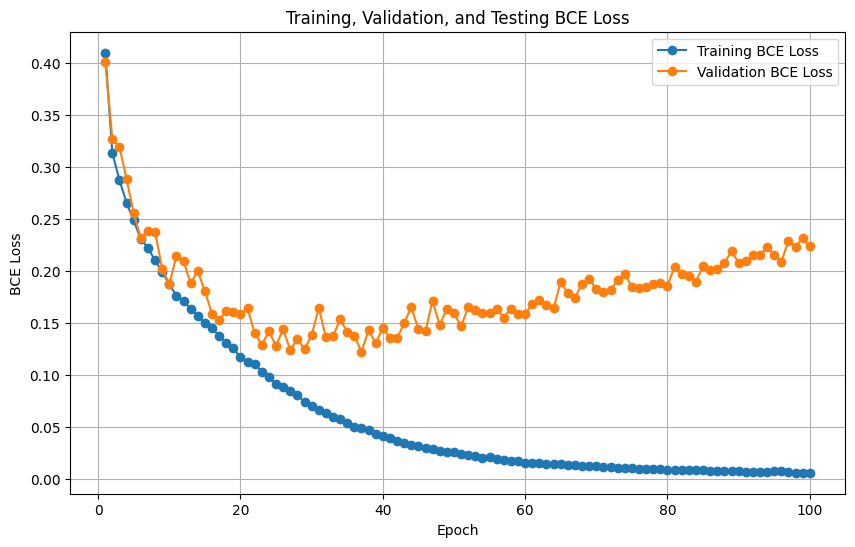

In [107]:
import matplotlib.pyplot as plt

train_epochs = range(1, len(train_bce_losses) + 1)
val_epochs = range(1, len(val_bce_losses) + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    train_epochs,
    train_bce_losses,
    marker="o",
    label="Training BCE Loss"
)

plt.plot(
    val_epochs,
    val_bce_losses,
    marker="o",
    label="Validation BCE Loss"
)



plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training, Validation, and Testing BCE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [92]:
import torch

model_v2.eval()

total_dice = 0.0
num_batches = 0
smooth = 1e-7

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device).float()

        outputs = model_v2(images)
        predictions = (torch.sigmoid(outputs) > 0.5).float()

        intersection = (predictions * masks).sum(dim=(1, 2, 3))
        union = predictions.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3))

        dice = (2 * intersection + smooth) / (union + smooth)

        total_dice += dice.mean().item()
        num_batches += 1

test_dice = total_dice / num_batches

print(f"Testing Dice Score: {test_dice:.4f}")

Testing Dice Score: 0.9017


In [94]:
import torch

# Load the best trained model
model_v2.load_state_dict(
    torch.load(
        "/kaggle/working/best_unet_v2.pth",
        map_location=device
    )
)

model_v2 = model_v2.to(device)
model_v2.eval()

total_intersection = 0.0
total_union = 0.0
smooth = 1e-7

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device).float()

        # Generate predictions
        outputs = model_v2(images)
        probabilities = torch.sigmoid(outputs)
        predictions = (probabilities > 0.5).float()

        # Calculate intersection and union
        intersection = (predictions * masks).sum()
        union = ((predictions + masks) > 0).float().sum()

        total_intersection += intersection.item()
        total_union += union.item()

# Calculate final test IoU
test_iou = (
    total_intersection + smooth
) / (
    total_union + smooth
)

print(f"Testing IoU: {test_iou:.4f}")
print(f"Testing IoU (%): {test_iou * 100:.2f}%")

Testing IoU: 0.8305
Testing IoU (%): 83.05%


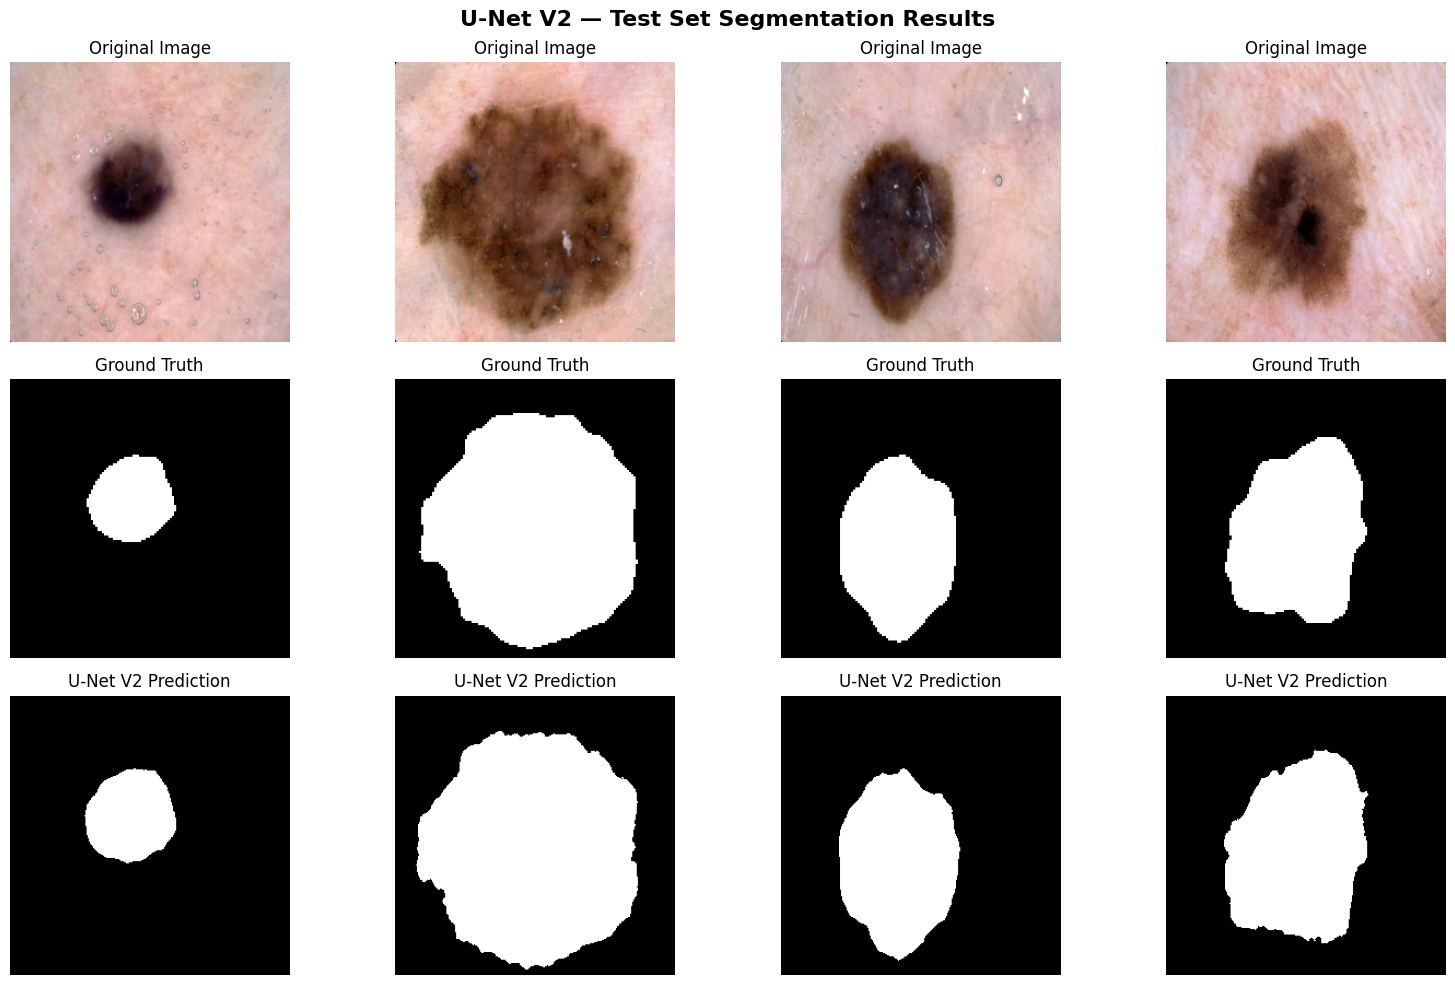

In [106]:

import torch
import matplotlib.pyplot as plt

# ============================================================
# LOAD BEST MODEL
# ============================================================

model_v2.load_state_dict(
    torch.load(
        "/kaggle/working/best_unet_v2.pth",
        map_location=device
    )
)

model_v2 = model_v2.to(device)
model_v2.eval()



# ============================================================
# GET ONE BATCH FROM TESTING DATASET
# ============================================================

images, masks = next(iter(test_loader))

images = images.to(device)
masks = masks.to(device)


# ============================================================
# GENERATE PREDICTIONS
# ============================================================

with torch.no_grad():

    predictions = model_v2(images)

    probabilities = torch.sigmoid(predictions)

    predictions_binary = (
        probabilities > 0.5
    ).float()


# ============================================================
# MOVE TENSORS TO CPU
# ============================================================

images = images.cpu()
masks = masks.cpu()
predictions_binary = predictions_binary.cpu()


# ============================================================
# VISUALIZE RESULTS
# ============================================================

num_images = min(4, images.shape[0])

plt.figure(figsize=(4 * num_images, 9))

for i in range(num_images):

    # --------------------------------------------------------
    # ORIGINAL IMAGE
    # --------------------------------------------------------

    plt.subplot(3, num_images, i + 1)

    image = images[i].permute(1, 2, 0)

    plt.imshow(image)

    plt.title("Original Image")

    plt.axis("off")


    # --------------------------------------------------------
    # GROUND-TRUTH MASK
    # --------------------------------------------------------

    plt.subplot(
        3,
        num_images,
        num_images + i + 1
    )

    plt.imshow(
        masks[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title("Ground Truth")

    plt.axis("off")


    # --------------------------------------------------------
    # PREDICTED MASK
    # --------------------------------------------------------

    plt.subplot(
        3,
        num_images,
        2 * num_images + i + 1
    )

    plt.imshow(
        predictions_binary[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title("U-Net V2 Test Set Segmentation Result")

    plt.axis("off")


plt.tight_layout()
plt.show()


In [108]:

import torch
import torch.nn as nn

class UNetV1(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder1 = EncoderBlock(3, 64)
        self.encoder2 = EncoderBlock(64, 128)
        self.encoder3 = EncoderBlock(128, 256)
        self.encoder4 = EncoderBlock(256, 512)

        # Bottleneck
        self.bottleneck = DoubleConv(512, 1024)

        # Decoder with standard skip connections
        self.decoder1 = DecoderBlock(1024, 512)
        self.decoder2 = DecoderBlock(512, 256)
        self.decoder3 = DecoderBlock(256, 128)
        self.decoder4 = DecoderBlock(128, 64)

        # Segmentation output
        self.final_conv = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        # Encoder
        features1, pooled1 = self.encoder1(x)
        features2, pooled2 = self.encoder2(pooled1)
        features3, pooled3 = self.encoder3(pooled2)
        features4, pooled4 = self.encoder4(pooled3)

        # Bottleneck
        bottleneck = self.bottleneck(pooled4)

        # Decoder
        decoder1 = self.decoder1(bottleneck, features4)
        decoder2 = self.decoder2(decoder1, features3)
        decoder3 = self.decoder3(decoder2, features2)
        decoder4 = self.decoder4(decoder3, features1)

        return self.final_conv(decoder4)


device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

model_v1 = UNetV1().to(device)

print("U-Net V1 created successfully")
print("Device:", device)


U-Net V1 created successfully
Device: cuda:0


Using existing V2 data split
Training samples: 1611
Validation samples: 179
Test samples: 210
Available GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


Caching Training:   0%|          | 0/1611 [00:00<?, ?it/s]

Training: 1611 samples loaded into RAM


Caching Validation:   0%|          | 0/179 [00:00<?, ?it/s]

Validation: 179 samples loaded into RAM


Caching Testing:   0%|          | 0/210 [00:00<?, ?it/s]

... (301 outputs left out)

Testing U-Net V1:   0%|          | 0/14 [00:00<?, ?it/s]

U-Net V1 Testing Dice Score: 0.8814
U-Net V1 Testing IoU: 0.8025


Testing U-Net V2:   0%|          | 0/14 [00:00<?, ?it/s]

U-Net V2 Testing Dice Score: 0.8823
U-Net V2 Testing IoU: 0.8045

TEST SET COMPARISON
Dice | V1: 0.8814 | V2: 0.8823
IoU  | V1: 0.8025 | V2: 0.8045


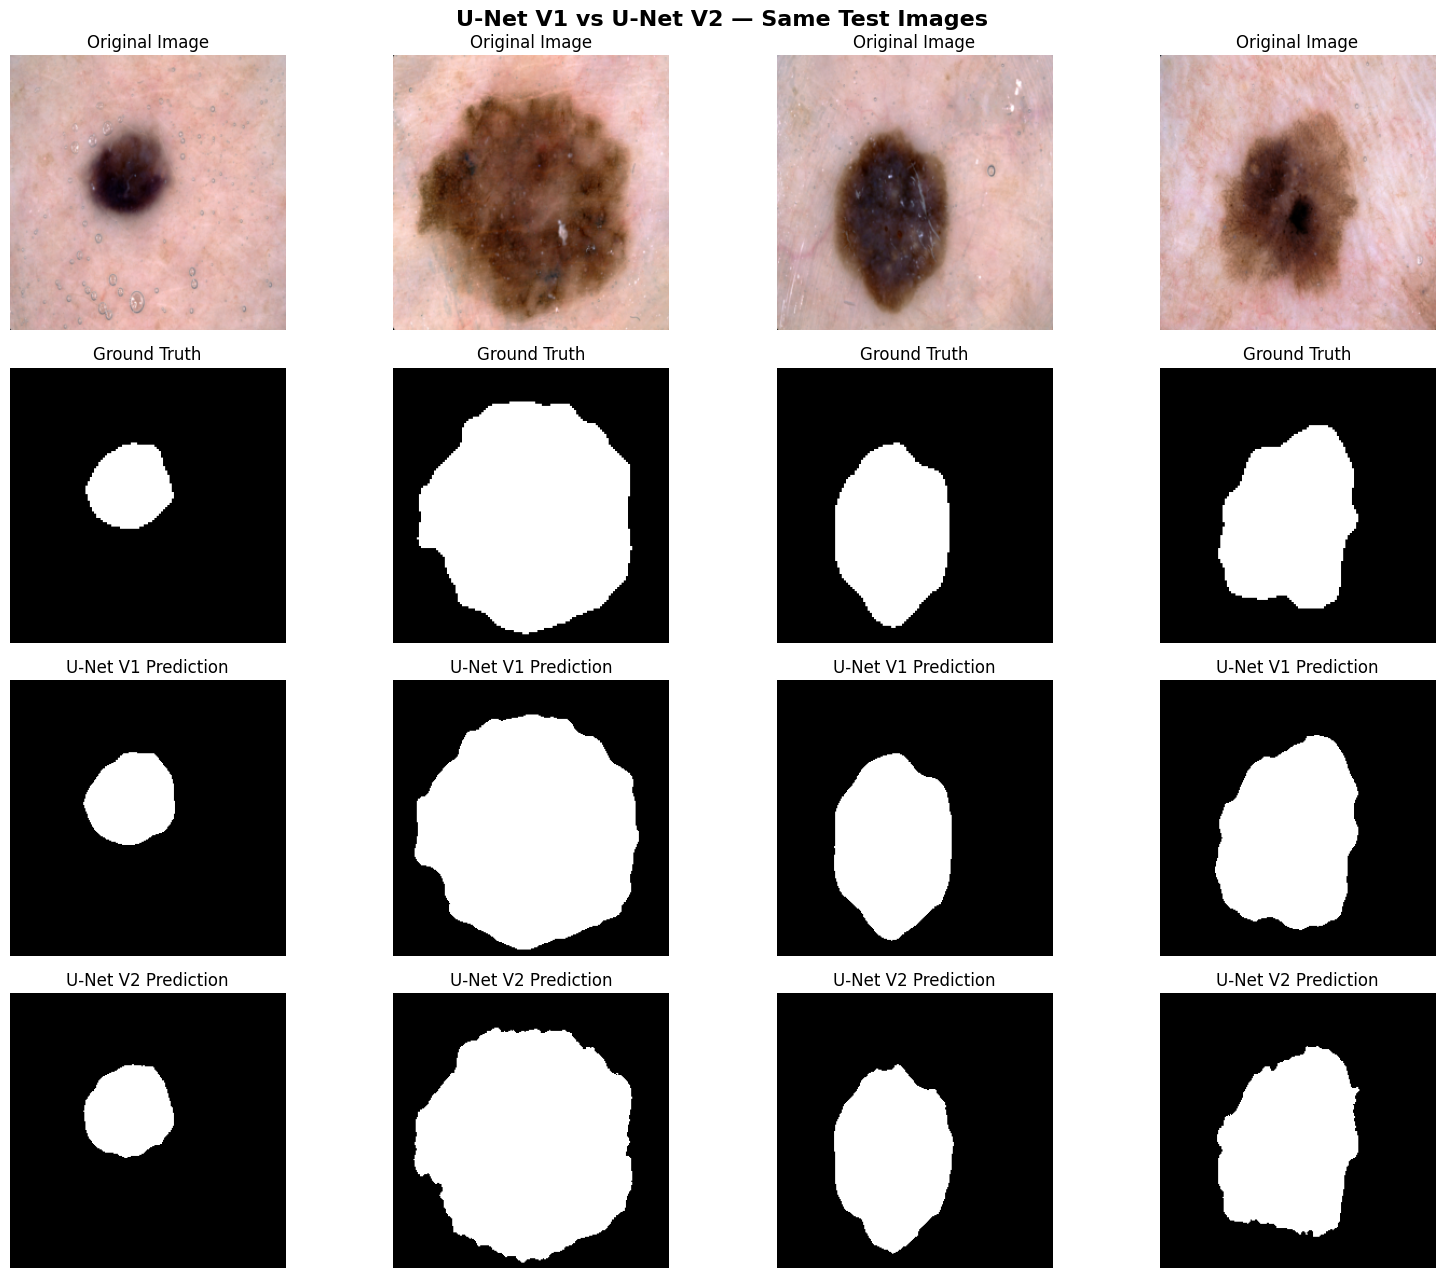

In [116]:

# ============================================================
# U-NET V1: TRAIN + TEST + V1/V2 VISUAL COMPARISON
# Uses the SAME existing data split as U-Net V2
# ============================================================

import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. CHECK EXISTING DATA SPLIT AND V2 MODEL
# ------------------------------------------------------------

assert all(name in globals() for name in [
    "train_df", "val_df", "test_df", "ISICDataset", "model_v2"
]), "Run your original V2 dataset split and model-definition cells first."

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Using existing V2 data split")
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))
print("Available GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

# ------------------------------------------------------------
# 2. LOAD ALL DATA INTO RAM
# ------------------------------------------------------------

class V1RAMDataset(Dataset):
    def __init__(self, source, name):
        self.images = []
        self.masks = []

        for idx in tqdm(range(len(source)), desc=f"Caching {name}"):
            image, mask = source[idx]
            self.images.append(image.contiguous())
            self.masks.append(mask.contiguous())

        print(f"{name}: {len(self.images)} samples loaded into RAM")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.masks[idx]


train_disk = ISICDataset(train_df)
val_disk = ISICDataset(val_df)
test_disk = ISICDataset(test_df)

train_data = V1RAMDataset(train_disk, "Training")
val_data = V1RAMDataset(val_disk, "Validation")
test_data = V1RAMDataset(test_disk, "Testing")

BATCH_SIZE = 16

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)
test_loader = DataLoader(
    test_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)

# ------------------------------------------------------------
# 3. ORIGINAL U-NET V1 ARCHITECTURE
# ------------------------------------------------------------

class V1DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class V1Encoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = V1DoubleConv(in_channels, out_channels)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        features = self.conv(x)
        return features, self.pool(features)


class V1Decoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(
            in_channels, out_channels, kernel_size=2, stride=2
        )
        self.conv = V1DoubleConv(out_channels * 2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class UNetV1(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = V1Encoder(3, 64)
        self.enc2 = V1Encoder(64, 128)
        self.enc3 = V1Encoder(128, 256)
        self.enc4 = V1Encoder(256, 512)

        self.bottleneck = V1DoubleConv(512, 1024)

        self.dec4 = V1Decoder(1024, 512)
        self.dec3 = V1Decoder(512, 256)
        self.dec2 = V1Decoder(256, 128)
        self.dec1 = V1Decoder(128, 64)

        self.final_conv = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        f1, p1 = self.enc1(x)
        f2, p2 = self.enc2(p1)
        f3, p3 = self.enc3(p2)
        f4, p4 = self.enc4(p3)

        b = self.bottleneck(p4)

        x = self.dec4(b, f4)
        x = self.dec3(x, f3)
        x = self.dec2(x, f2)
        x = self.dec1(x, f1)

        return self.final_conv(x)


# ------------------------------------------------------------
# 4. LOSS, METRICS AND MODEL SETUP
# ------------------------------------------------------------

def v1_combined_loss(logits, targets):
    bce = nn.functional.binary_cross_entropy_with_logits(
        logits, targets
    )

    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probs * targets).sum(dim=dims)

    dice = (
        2 * intersection + 1e-7
    ) / (
        probs.sum(dim=dims) + targets.sum(dim=dims) + 1e-7
    )

    return bce + (1 - dice).mean()


def calculate_metrics(logits, targets):
    predictions = (torch.sigmoid(logits) > 0.5).float()
    dims = (1, 2, 3)

    intersection = (predictions * targets).sum(dim=dims)
    pred_sum = predictions.sum(dim=dims)
    target_sum = targets.sum(dim=dims)
    union = ((predictions + targets) > 0).float().sum(dim=dims)

    dice = (2 * intersection + 1e-7) / (
        pred_sum + target_sum + 1e-7
    )
    iou = (intersection + 1e-7) / (union + 1e-7)

    return dice, iou


model_v1 = UNetV1().to(device)

if torch.cuda.device_count() >= 2:
    model_v1 = nn.DataParallel(model_v1, device_ids=[0, 1])
    print("U-Net V1 configured for both T4 GPUs.")
else:
    print("U-Net V1 configured for the available device.")

optimizer_v1 = torch.optim.Adam(model_v1.parameters(), lr=1e-5)

scaler_v1 = (
    torch.amp.GradScaler("cuda")
    if device.type == "cuda" else None
)

best_model_path_v1 = "/kaggle/working/best_unet_v1.pth"
num_epochs_v1 = 100
best_val_dice_v1 = -1.0

train_losses_v1 = []
val_losses_v1 = []
val_dice_v1 = []
val_iou_v1 = []

# ------------------------------------------------------------
# 5. TRAIN V1 WITH PROGRESS BARS
# ------------------------------------------------------------

for epoch in range(num_epochs_v1):
    model_v1.train()
    running_train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs_v1} [Train]"
    )

    for images, masks in train_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True).float()

        optimizer_v1.zero_grad(set_to_none=True)

        if device.type == "cuda":
            with torch.amp.autocast("cuda"):
                outputs = model_v1(images)
                loss = v1_combined_loss(outputs, masks)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss detected.")

            scaler_v1.scale(loss).backward()
            scaler_v1.unscale_(optimizer_v1)
            nn.utils.clip_grad_norm_(model_v1.parameters(), 0.1)
            scaler_v1.step(optimizer_v1)
            scaler_v1.update()
        else:
            outputs = model_v1(images)
            loss = v1_combined_loss(outputs, masks)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss detected.")

            loss.backward()
            nn.utils.clip_grad_norm_(model_v1.parameters(), 0.1)
            optimizer_v1.step()

        running_train_loss += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = running_train_loss / len(train_loader)
    train_losses_v1.append(avg_train_loss)

    # ---------------- VALIDATION ----------------
    model_v1.eval()
    running_val_loss = 0.0
    dice_values = []
    iou_values = []

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch+1}/{num_epochs_v1} [Validation]"
    )

    with torch.no_grad():
        for images, masks in val_bar:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True).float()

            if device.type == "cuda":
                with torch.amp.autocast("cuda"):
                    outputs = model_v1(images)
                    loss = v1_combined_loss(outputs, masks)
            else:
                outputs = model_v1(images)
                loss = v1_combined_loss(outputs, masks)

            running_val_loss += loss.item()
            dice, iou = calculate_metrics(outputs, masks)

            dice_values.extend(dice.cpu().tolist())
            iou_values.extend(iou.cpu().tolist())
            val_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_val_loss = running_val_loss / len(val_loader)
    avg_val_dice = sum(dice_values) / len(dice_values)
    avg_val_iou = sum(iou_values) / len(iou_values)

    val_losses_v1.append(avg_val_loss)
    val_dice_v1.append(avg_val_dice)
    val_iou_v1.append(avg_val_iou)

    if avg_val_dice > best_val_dice_v1:
        best_val_dice_v1 = avg_val_dice

        base_model = (
            model_v1.module
            if isinstance(model_v1, nn.DataParallel)
            else model_v1
        )

        torch.save(base_model.state_dict(), best_model_path_v1)
        print(f"Best V1 checkpoint saved: epoch {epoch+1}")

    print(
        f"Epoch {epoch+1}/{num_epochs_v1} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Dice: {avg_val_dice:.4f} | "
        f"Val IoU: {avg_val_iou:.4f}"
    )

print("\nV1 training complete.")
print(f"Best validation Dice: {best_val_dice_v1:.4f}")

# ------------------------------------------------------------
# 6. LOAD BEST V1 AND EXISTING V2 CHECKPOINT
# ------------------------------------------------------------

base_v1 = (
    model_v1.module
    if isinstance(model_v1, nn.DataParallel)
    else model_v1
)
base_v1.load_state_dict(
    torch.load(best_model_path_v1, map_location=device)
)
model_v1.eval()

v2_checkpoint_path = "/kaggle/working/best_unet_v2.pth"
assert os.path.exists(v2_checkpoint_path), (
    "V2 checkpoint not found. Make sure best_unet_v2.pth exists."
)

base_v2 = (
    model_v2.module
    if isinstance(model_v2, nn.DataParallel)
    else model_v2
)
base_v2.load_state_dict(
    torch.load(v2_checkpoint_path, map_location=device)
)
model_v2.eval()

# ------------------------------------------------------------
# 7. TEST BOTH MODELS ON THE SAME TEST SET
# ------------------------------------------------------------

def evaluate_model(model, loader, name):
    model.eval()
    all_dice = []
    all_iou = []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc=f"Testing {name}"):
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True).float()

            outputs = model(images)
            dice, iou = calculate_metrics(outputs, masks)

            all_dice.extend(dice.cpu().tolist())
            all_iou.extend(iou.cpu().tolist())

    mean_dice = sum(all_dice) / len(all_dice)
    mean_iou = sum(all_iou) / len(all_iou)

    print(f"{name} Testing Dice Score: {mean_dice:.4f}")
    print(f"{name} Testing IoU: {mean_iou:.4f}")

    return mean_dice, mean_iou


dice_v1, iou_v1 = evaluate_model(base_v1, test_loader, "U-Net V1")
dice_v2, iou_v2 = evaluate_model(base_v2, test_loader, "U-Net V2")

print("\nTEST SET COMPARISON")
print(f"Dice | V1: {dice_v1:.4f} | V2: {dice_v2:.4f}")
print(f"IoU  | V1: {iou_v1:.4f} | V2: {iou_v2:.4f}")

# ------------------------------------------------------------
# 8. VISUALIZE THE SAME FOUR TEST IMAGES USED PREVIOUSLY
# ------------------------------------------------------------
# These are zero-based indices into test_data:
# previously selected 1-based sample numbers: 177, 141, 130, 156.

test_indices = [176, 140, 129, 155]

assert max(test_indices) < len(test_data), (
    "One or more selected test indices are outside the test dataset."
)

images_to_show = []
masks_to_show = []
preds_v1 = []
preds_v2 = []

with torch.no_grad():
    for idx in test_indices:
        image, mask = test_data[idx]
        input_tensor = image.unsqueeze(0).to(device)

        out_v1 = base_v1(input_tensor)
        out_v2 = base_v2(input_tensor)

        pred_v1 = (torch.sigmoid(out_v1) > 0.5).float()
        pred_v2 = (torch.sigmoid(out_v2) > 0.5).float()

        images_to_show.append(image.cpu())
        masks_to_show.append(mask.cpu())
        preds_v1.append(pred_v1.squeeze(0).cpu())
        preds_v2.append(pred_v2.squeeze(0).cpu())

# Four rows: original, ground truth, V1, V2
num_images = len(test_indices)
fig, axes = plt.subplots(
    4, num_images,
    figsize=(4 * num_images, 13)
)

row_titles = [
    "Original Image",
    "Ground Truth",
    "U-Net V1 Prediction",
    "U-Net V2 Prediction"
]

for i in range(num_images):
    axes[0, i].imshow(images_to_show[i].permute(1, 2, 0))
    axes[1, i].imshow(masks_to_show[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[2, i].imshow(preds_v1[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[3, i].imshow(preds_v2[i].squeeze(), cmap="gray", vmin=0, vmax=1)

    for r in range(4):
        axes[r, i].set_title(row_titles[r])
        axes[r, i].axis("off")

plt.suptitle(
    "U-Net V1 vs U-Net V2 — Same Test Images",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


In [132]:
model_path = "/kaggle/working/best_unet_v1.pth"

state_dict = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

if isinstance(model_v1, torch.nn.DataParallel):
    model_v1.module.load_state_dict(state_dict)
else:
    model_v1.load_state_dict(state_dict)

model_v1.eval()

print("U-Net V1 checkpoint loaded successfully.")

U-Net V1 checkpoint loaded successfully.


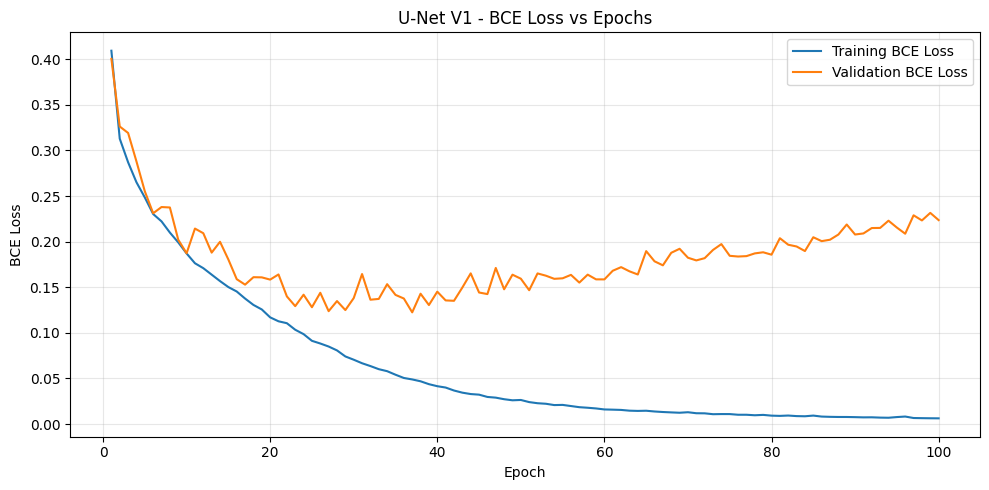

In [153]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_bce_losses) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs, train_bce_losses, label="Training BCE Loss")
plt.plot(epochs, val_bce_losses, label="Validation BCE Loss")

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("U-Net V1 - BCE Loss vs Epochs")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [2]:

# ============================================================
# U-NET V1: TRAIN + TEST + V1/V2 VISUAL COMPARISON
# Uses the SAME existing data split as U-Net V2
# ============================================================

import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. CHECK EXISTING DATA SPLIT AND V2 MODEL
# ------------------------------------------------------------

assert all(name in globals() for name in [
    "train_df", "val_df", "test_df", "ISICDataset", "model_v2"
]), "Run your original V2 dataset split and model-definition cells first."

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Using existing V2 data split")
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))
print("Available GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

# ------------------------------------------------------------
# 2. LOAD ALL DATA INTO RAM
# ------------------------------------------------------------

class V1RAMDataset(Dataset):
    def __init__(self, source, name):
        self.images = []
        self.masks = []

        for idx in tqdm(range(len(source)), desc=f"Caching {name}"):
            image, mask = source[idx]
            self.images.append(image.contiguous())
            self.masks.append(mask.contiguous())

        print(f"{name}: {len(self.images)} samples loaded into RAM")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.masks[idx]


train_disk = ISICDataset(train_df)
val_disk = ISICDataset(val_df)
test_disk = ISICDataset(test_df)

train_data = V1RAMDataset(train_disk, "Training")
val_data = V1RAMDataset(val_disk, "Validation")
test_data = V1RAMDataset(test_disk, "Testing")

BATCH_SIZE = 16

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)
test_loader = DataLoader(
    test_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)

# ------------------------------------------------------------
# 3. ORIGINAL U-NET V1 ARCHITECTURE
# ------------------------------------------------------------

class V1DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class V1Encoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = V1DoubleConv(in_channels, out_channels)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        features = self.conv(x)
        return features, self.pool(features)


class V1Decoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(
            in_channels, out_channels, kernel_size=2, stride=2
        )
        self.conv = V1DoubleConv(out_channels * 2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class UNetV1(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = V1Encoder(3, 64)
        self.enc2 = V1Encoder(64, 128)
        self.enc3 = V1Encoder(128, 256)
        self.enc4 = V1Encoder(256, 512)

        self.bottleneck = V1DoubleConv(512, 1024)

        self.dec4 = V1Decoder(1024, 512)
        self.dec3 = V1Decoder(512, 256)
        self.dec2 = V1Decoder(256, 128)
        self.dec1 = V1Decoder(128, 64)

        self.final_conv = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        f1, p1 = self.enc1(x)
        f2, p2 = self.enc2(p1)
        f3, p3 = self.enc3(p2)
        f4, p4 = self.enc4(p3)

        b = self.bottleneck(p4)

        x = self.dec4(b, f4)
        x = self.dec3(x, f3)
        x = self.dec2(x, f2)
        x = self.dec1(x, f1)

        return self.final_conv(x)


# ------------------------------------------------------------
# 4. LOSS, METRICS AND MODEL SETUP
# ------------------------------------------------------------

def v1_combined_loss(logits, targets):
    bce = nn.functional.binary_cross_entropy_with_logits(
        logits, targets
    )

    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probs * targets).sum(dim=dims)

    dice = (
        2 * intersection + 1e-7
    ) / (
        probs.sum(dim=dims) + targets.sum(dim=dims) + 1e-7
    )

    return bce + (1 - dice).mean()


def calculate_metrics(logits, targets):
    predictions = (torch.sigmoid(logits) > 0.5).float()
    dims = (1, 2, 3)

    intersection = (predictions * targets).sum(dim=dims)
    pred_sum = predictions.sum(dim=dims)
    target_sum = targets.sum(dim=dims)
    union = ((predictions + targets) > 0).float().sum(dim=dims)

    dice = (2 * intersection + 1e-7) / (
        pred_sum + target_sum + 1e-7
    )
    iou = (intersection + 1e-7) / (union + 1e-7)

    return dice, iou


model_v1 = UNetV1().to(device)

if torch.cuda.device_count() >= 2:
    model_v1 = nn.DataParallel(model_v1, device_ids=[0, 1])
    print("U-Net V1 configured for both T4 GPUs.")
else:
    print("U-Net V1 configured for the available device.")

optimizer_v1 = torch.optim.Adam(model_v1.parameters(), lr=1e-5)

scaler_v1 = (
    torch.amp.GradScaler("cuda")
    if device.type == "cuda" else None
)

best_model_path_v1 = "/kaggle/working/best_unet_v1.pth"
num_epochs_v1 = 100
best_val_dice_v1 = -1.0

train_losses_v1 = []
val_losses_v1 = []
val_dice_v1 = []
val_iou_v1 = []

# ------------------------------------------------------------
# 5. TRAIN V1 WITH PROGRESS BARS
# ------------------------------------------------------------

for epoch in range(num_epochs_v1):
    model_v1.train()
    running_train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs_v1} [Train]"
    )

    for images, masks in train_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True).float()

        optimizer_v1.zero_grad(set_to_none=True)

        if device.type == "cuda":
            with torch.amp.autocast("cuda"):
                outputs = model_v1(images)
                loss = v1_combined_loss(outputs, masks)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss detected.")

            scaler_v1.scale(loss).backward()
            scaler_v1.unscale_(optimizer_v1)
            nn.utils.clip_grad_norm_(model_v1.parameters(), 0.1)
            scaler_v1.step(optimizer_v1)
            scaler_v1.update()
        else:
            outputs = model_v1(images)
            loss = v1_combined_loss(outputs, masks)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss detected.")

            loss.backward()
            nn.utils.clip_grad_norm_(model_v1.parameters(), 0.1)
            optimizer_v1.step()

        running_train_loss += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = running_train_loss / len(train_loader)
    train_losses_v1.append(avg_train_loss)

    # ---------------- VALIDATION ----------------
    model_v1.eval()
    running_val_loss = 0.0
    dice_values = []
    iou_values = []

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch+1}/{num_epochs_v1} [Validation]"
    )

    with torch.no_grad():
        for images, masks in val_bar:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True).float()

            if device.type == "cuda":
                with torch.amp.autocast("cuda"):
                    outputs = model_v1(images)
                    loss = v1_combined_loss(outputs, masks)
            else:
                outputs = model_v1(images)
                loss = v1_combined_loss(outputs, masks)

            running_val_loss += loss.item()
            dice, iou = calculate_metrics(outputs, masks)

            dice_values.extend(dice.cpu().tolist())
            iou_values.extend(iou.cpu().tolist())
            val_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_val_loss = running_val_loss / len(val_loader)
    avg_val_dice = sum(dice_values) / len(dice_values)
    avg_val_iou = sum(iou_values) / len(iou_values)

    val_losses_v1.append(avg_val_loss)
    val_dice_v1.append(avg_val_dice)
    val_iou_v1.append(avg_val_iou)

    if avg_val_dice > best_val_dice_v1:
        best_val_dice_v1 = avg_val_dice

        base_model = (
            model_v1.module
            if isinstance(model_v1, nn.DataParallel)
            else model_v1
        )

        torch.save(base_model.state_dict(), best_model_path_v1)
        print(f"Best V1 checkpoint saved: epoch {epoch+1}")

    print(
        f"Epoch {epoch+1}/{num_epochs_v1} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Dice: {avg_val_dice:.4f} | "
        f"Val IoU: {avg_val_iou:.4f}"
    )

print("\nV1 training complete.")
print(f"Best validation Dice: {best_val_dice_v1:.4f}")

# ------------------------------------------------------------
# 6. LOAD BEST V1 AND EXISTING V2 CHECKPOINT
# ------------------------------------------------------------

base_v1 = (
    model_v1.module
    if isinstance(model_v1, nn.DataParallel)
    else model_v1
)
base_v1.load_state_dict(
    torch.load(best_model_path_v1, map_location=device)
)
model_v1.eval()

v2_checkpoint_path = "/kaggle/working/best_unet_v2.pth"
assert os.path.exists(v2_checkpoint_path), (
    "V2 checkpoint not found. Make sure best_unet_v2.pth exists."
)

base_v2 = (
    model_v2.module
    if isinstance(model_v2, nn.DataParallel)
    else model_v2
)
base_v2.load_state_dict(
    torch.load(v2_checkpoint_path, map_location=device)
)
model_v2.eval()

# ------------------------------------------------------------
# 7. TEST BOTH MODELS ON THE SAME TEST SET
# ------------------------------------------------------------

def evaluate_model(model, loader, name):
    model.eval()
    all_dice = []
    all_iou = []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc=f"Testing {name}"):
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True).float()

            outputs = model(images)
            dice, iou = calculate_metrics(outputs, masks)

            all_dice.extend(dice.cpu().tolist())
            all_iou.extend(iou.cpu().tolist())

    mean_dice = sum(all_dice) / len(all_dice)
    mean_iou = sum(all_iou) / len(all_iou)

    print(f"{name} Testing Dice Score: {mean_dice:.4f}")
    print(f"{name} Testing IoU: {mean_iou:.4f}")

    return mean_dice, mean_iou


dice_v1, iou_v1 = evaluate_model(base_v1, test_loader, "U-Net V1")
dice_v2, iou_v2 = evaluate_model(base_v2, test_loader, "U-Net V2")

print("\nTEST SET COMPARISON")
print(f"Dice | V1: {dice_v1:.4f} | V2: {dice_v2:.4f}")
print(f"IoU  | V1: {iou_v1:.4f} | V2: {iou_v2:.4f}")

# ------------------------------------------------------------
# 8. VISUALIZE THE SAME FOUR TEST IMAGES USED PREVIOUSLY
# ------------------------------------------------------------
# These are zero-based indices into test_data:
# previously selected 1-based sample numbers: 177, 141, 130, 156.

test_indices = [176, 140, 129, 155]

assert max(test_indices) < len(test_data), (
    "One or more selected test indices are outside the test dataset."
)

images_to_show = []
masks_to_show = []
preds_v1 = []
preds_v2 = []

with torch.no_grad():
    for idx in test_indices:
        image, mask = test_data[idx]
        input_tensor = image.unsqueeze(0).to(device)

        out_v1 = base_v1(input_tensor)
        out_v2 = base_v2(input_tensor)

        pred_v1 = (torch.sigmoid(out_v1) > 0.5).float()
        pred_v2 = (torch.sigmoid(out_v2) > 0.5).float()

        images_to_show.append(image.cpu())
        masks_to_show.append(mask.cpu())
        preds_v1.append(pred_v1.squeeze(0).cpu())
        preds_v2.append(pred_v2.squeeze(0).cpu())

# Four rows: original, ground truth, V1, V2
num_images = len(test_indices)
fig, axes = plt.subplots(
    4, num_images,
    figsize=(4 * num_images, 13)
)

row_titles = [
    "Original Image",
    "Ground Truth",
    "U-Net V1 Prediction",
    "U-Net V2 Prediction"
]

for i in range(num_images):
    axes[0, i].imshow(images_to_show[i].permute(1, 2, 0))
    axes[1, i].imshow(masks_to_show[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[2, i].imshow(preds_v1[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[3, i].imshow(preds_v2[i].squeeze(), cmap="gray", vmin=0, vmax=1)

    for r in range(4):
        axes[r, i].set_title(row_titles[r])
        axes[r, i].axis("off")

plt.suptitle(
    "U-Net V1 vs U-Net V2 — Same Test Images",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


    Using existing V2 data split
Training samples: 1611
Validation samples: 179
Test samples: 210
Available GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Caching Training: 100%
 1611/1611 [02:48<00:00,  8.78it/s]
Training: 1611 samples loaded into RAM
Caching Validation: 100%
 179/179 [00:18<00:00, 10.31it/s]
Validation: 179 samples loaded into RAM
Caching Testing: 100%
 210/210 [01:20<00:00,  1.68it/s]
Testing: 210 samples loaded into RAM
U-Net V1 configured for both T4 GPUs.
Epoch 1/100 [Train]: 100%
 101/101 [00:30<00:00,  3.77it/s, loss=1.1221]
Epoch 1/100 [Validation]: 100%
 12/12 [00:01<00:00,  9.69it/s, loss=0.7855]
Best V1 checkpoint saved: epoch 1
Epoch 1/100 | Train Loss: 1.2225 | Val Loss: 1.0775 | Val Dice: 0.6649 | Val IoU: 0.5505
Epoch 2/100 [Train]: 100%
 101/101 [00:27<00:00,  3.92it/s, loss=0.8011]
Epoch 2/100 [Validation]: 100%
 12/12 [00:01<00:00, 11.19it/s, loss=0.6951]
Best V1 checkpoint saved: epoch 2
Epoch 2/100 | Train Loss: 1.0000 | Val Loss: 0.9528 | Val Dice: 0.75

In [ ]:

# ============================================================
# U-NET V1: TRAIN + TEST + V1/V2 VISUAL COMPARISON
# Uses the SAME existing data split as U-Net V2
# ============================================================

import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. CHECK EXISTING DATA SPLIT AND V2 MODEL
# ------------------------------------------------------------

assert all(name in globals() for name in [
    "train_df", "val_df", "test_df", "ISICDataset", "model_v2"
]), "Run your original V2 dataset split and model-definition cells first."

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Using existing V2 data split")
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))
print("Available GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

# ------------------------------------------------------------
# 2. LOAD ALL DATA INTO RAM
# ------------------------------------------------------------

class V1RAMDataset(Dataset):
    def __init__(self, source, name):
        self.images = []
        self.masks = []

        for idx in tqdm(range(len(source)), desc=f"Caching {name}"):
            image, mask = source[idx]
            self.images.append(image.contiguous())
            self.masks.append(mask.contiguous())

        print(f"{name}: {len(self.images)} samples loaded into RAM")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.masks[idx]


train_disk = ISICDataset(train_df)
val_disk = ISICDataset(val_df)
test_disk = ISICDataset(test_df)

train_data = V1RAMDataset(train_disk, "Training")
val_data = V1RAMDataset(val_disk, "Validation")
test_data = V1RAMDataset(test_disk, "Testing")

BATCH_SIZE = 16

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)
test_loader = DataLoader(
    test_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)

# ------------------------------------------------------------
# 3. ORIGINAL U-NET V1 ARCHITECTURE
# ------------------------------------------------------------

class V1DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class V1Encoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = V1DoubleConv(in_channels, out_channels)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        features = self.conv(x)
        return features, self.pool(features)


class V1Decoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(
            in_channels, out_channels, kernel_size=2, stride=2
        )
        self.conv = V1DoubleConv(out_channels * 2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class UNetV1(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = V1Encoder(3, 64)
        self.enc2 = V1Encoder(64, 128)
        self.enc3 = V1Encoder(128, 256)
        self.enc4 = V1Encoder(256, 512)

        self.bottleneck = V1DoubleConv(512, 1024)

        self.dec4 = V1Decoder(1024, 512)
        self.dec3 = V1Decoder(512, 256)
        self.dec2 = V1Decoder(256, 128)
        self.dec1 = V1Decoder(128, 64)

        self.final_conv = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        f1, p1 = self.enc1(x)
        f2, p2 = self.enc2(p1)
        f3, p3 = self.enc3(p2)
        f4, p4 = self.enc4(p3)

        b = self.bottleneck(p4)

        x = self.dec4(b, f4)
        x = self.dec3(x, f3)
        x = self.dec2(x, f2)
        x = self.dec1(x, f1)

        return self.final_conv(x)


# ------------------------------------------------------------
# 4. LOSS, METRICS AND MODEL SETUP
# ------------------------------------------------------------

def v1_combined_loss(logits, targets):
    bce = nn.functional.binary_cross_entropy_with_logits(
        logits, targets
    )

    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probs * targets).sum(dim=dims)

    dice = (
        2 * intersection + 1e-7
    ) / (
        probs.sum(dim=dims) + targets.sum(dim=dims) + 1e-7
    )

    return bce + (1 - dice).mean()


def calculate_metrics(logits, targets):
    predictions = (torch.sigmoid(logits) > 0.5).float()
    dims = (1, 2, 3)

    intersection = (predictions * targets).sum(dim=dims)
    pred_sum = predictions.sum(dim=dims)
    target_sum = targets.sum(dim=dims)
    union = ((predictions + targets) > 0).float().sum(dim=dims)

    dice = (2 * intersection + 1e-7) / (
        pred_sum + target_sum + 1e-7
    )
    iou = (intersection + 1e-7) / (union + 1e-7)

    return dice, iou


model_v1 = UNetV1().to(device)

if torch.cuda.device_count() >= 2:
    model_v1 = nn.DataParallel(model_v1, device_ids=[0, 1])
    print("U-Net V1 configured for both T4 GPUs.")
else:
    print("U-Net V1 configured for the available device.")

optimizer_v1 = torch.optim.Adam(model_v1.parameters(), lr=1e-5)

scaler_v1 = (
    torch.amp.GradScaler("cuda")
    if device.type == "cuda" else None
)

best_model_path_v1 = "/kaggle/working/best_unet_v1.pth"
num_epochs_v1 = 100
best_val_dice_v1 = -1.0

train_losses_v1 = []
val_losses_v1 = []
val_dice_v1 = []
val_iou_v1 = []

# ------------------------------------------------------------
# 5. TRAIN V1 WITH PROGRESS BARS
# ------------------------------------------------------------

for epoch in range(num_epochs_v1):
    model_v1.train()
    running_train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs_v1} [Train]"
    )

    for images, masks in train_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True).float()

        optimizer_v1.zero_grad(set_to_none=True)

        if device.type == "cuda":
            with torch.amp.autocast("cuda"):
                outputs = model_v1(images)
                loss = v1_combined_loss(outputs, masks)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss detected.")

            scaler_v1.scale(loss).backward()
            scaler_v1.unscale_(optimizer_v1)
            nn.utils.clip_grad_norm_(model_v1.parameters(), 0.1)
            scaler_v1.step(optimizer_v1)
            scaler_v1.update()
        else:
            outputs = model_v1(images)
            loss = v1_combined_loss(outputs, masks)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss detected.")

            loss.backward()
            nn.utils.clip_grad_norm_(model_v1.parameters(), 0.1)
            optimizer_v1.step()

        running_train_loss += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = running_train_loss / len(train_loader)
    train_losses_v1.append(avg_train_loss)

    # ---------------- VALIDATION ----------------
    model_v1.eval()
    running_val_loss = 0.0
    dice_values = []
    iou_values = []

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch+1}/{num_epochs_v1} [Validation]"
    )

    with torch.no_grad():
        for images, masks in val_bar:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True).float()

            if device.type == "cuda":
                with torch.amp.autocast("cuda"):
                    outputs = model_v1(images)
                    loss = v1_combined_loss(outputs, masks)
            else:
                outputs = model_v1(images)
                loss = v1_combined_loss(outputs, masks)

            running_val_loss += loss.item()
            dice, iou = calculate_metrics(outputs, masks)

            dice_values.extend(dice.cpu().tolist())
            iou_values.extend(iou.cpu().tolist())
            val_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_val_loss = running_val_loss / len(val_loader)
    avg_val_dice = sum(dice_values) / len(dice_values)
    avg_val_iou = sum(iou_values) / len(iou_values)

    val_losses_v1.append(avg_val_loss)
    val_dice_v1.append(avg_val_dice)
    val_iou_v1.append(avg_val_iou)

    if avg_val_dice > best_val_dice_v1:
        best_val_dice_v1 = avg_val_dice

        base_model = (
            model_v1.module
            if isinstance(model_v1, nn.DataParallel)
            else model_v1
        )

        torch.save(base_model.state_dict(), best_model_path_v1)
        print(f"Best V1 checkpoint saved: epoch {epoch+1}")

    print(
        f"Epoch {epoch+1}/{num_epochs_v1} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Dice: {avg_val_dice:.4f} | "
        f"Val IoU: {avg_val_iou:.4f}"
    )

print("\nV1 training complete.")
print(f"Best validation Dice: {best_val_dice_v1:.4f}")

# ------------------------------------------------------------
# 6. LOAD BEST V1 AND EXISTING V2 CHECKPOINT
# ------------------------------------------------------------

base_v1 = (
    model_v1.module
    if isinstance(model_v1, nn.DataParallel)
    else model_v1
)
base_v1.load_state_dict(
    torch.load(best_model_path_v1, map_location=device)
)
model_v1.eval()

v2_checkpoint_path = "/kaggle/working/best_unet_v2.pth"
assert os.path.exists(v2_checkpoint_path), (
    "V2 checkpoint not found. Make sure best_unet_v2.pth exists."
)

base_v2 = (
    model_v2.module
    if isinstance(model_v2, nn.DataParallel)
    else model_v2
)
base_v2.load_state_dict(
    torch.load(v2_checkpoint_path, map_location=device)
)
model_v2.eval()

# ------------------------------------------------------------
# 7. TEST BOTH MODELS ON THE SAME TEST SET
# ------------------------------------------------------------

def evaluate_model(model, loader, name):
    model.eval()
    all_dice = []
    all_iou = []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc=f"Testing {name}"):
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True).float()

            outputs = model(images)
            dice, iou = calculate_metrics(outputs, masks)

            all_dice.extend(dice.cpu().tolist())
            all_iou.extend(iou.cpu().tolist())

    mean_dice = sum(all_dice) / len(all_dice)
    mean_iou = sum(all_iou) / len(all_iou)

    print(f"{name} Testing Dice Score: {mean_dice:.4f}")
    print(f"{name} Testing IoU: {mean_iou:.4f}")

    return mean_dice, mean_iou


dice_v1, iou_v1 = evaluate_model(base_v1, test_loader, "U-Net V1")
dice_v2, iou_v2 = evaluate_model(base_v2, test_loader, "U-Net V2")

print("\nTEST SET COMPARISON")
print(f"Dice | V1: {dice_v1:.4f} | V2: {dice_v2:.4f}")
print(f"IoU  | V1: {iou_v1:.4f} | V2: {iou_v2:.4f}")

# ------------------------------------------------------------
# 8. VISUALIZE THE SAME FOUR TEST IMAGES USED PREVIOUSLY
# ------------------------------------------------------------
# These are zero-based indices into test_data:
# previously selected 1-based sample numbers: 177, 141, 130, 156.

test_indices = [176, 140, 129, 155]

assert max(test_indices) < len(test_data), (
    "One or more selected test indices are outside the test dataset."
)

images_to_show = []
masks_to_show = []
preds_v1 = []
preds_v2 = []

with torch.no_grad():
    for idx in test_indices:
        image, mask = test_data[idx]
        input_tensor = image.unsqueeze(0).to(device)

        out_v1 = base_v1(input_tensor)
        out_v2 = base_v2(input_tensor)

        pred_v1 = (torch.sigmoid(out_v1) > 0.5).float()
        pred_v2 = (torch.sigmoid(out_v2) > 0.5).float()

        images_to_show.append(image.cpu())
        masks_to_show.append(mask.cpu())
        preds_v1.append(pred_v1.squeeze(0).cpu())
        preds_v2.append(pred_v2.squeeze(0).cpu())

# Four rows: original, ground truth, V1, V2
num_images = len(test_indices)
fig, axes = plt.subplots(
    4, num_images,
    figsize=(4 * num_images, 13)
)

row_titles = [
    "Original Image",
    "Ground Truth",
    "U-Net V1 Prediction",
    "U-Net V2 Prediction"
]

for i in range(num_images):
    axes[0, i].imshow(images_to_show[i].permute(1, 2, 0))
    axes[1, i].imshow(masks_to_show[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[2, i].imshow(preds_v1[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[3, i].imshow(preds_v2[i].squeeze(), cmap="gray", vmin=0, vmax=1)

    for r in range(4):
        axes[r, i].set_title(row_titles[r])
        axes[r, i].axis("off")

plt.suptitle(
    "U-Net V1 vs U-Net V2 — Same Test Images",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

# ============================================================
# U-NET V1: TRAIN + TEST + V1/V2 VISUAL COMPARISON
# Uses the SAME existing data split as U-Net V2
# ============================================================

import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. CHECK EXISTING DATA SPLIT AND V2 MODEL
# ------------------------------------------------------------

assert all(name in globals() for name in [
    "train_df", "val_df", "test_df", "ISICDataset", "model_v2"
]), "Run your original V2 dataset split and model-definition cells first."

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Using existing V2 data split")
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))
print("Available GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

# ------------------------------------------------------------
# 2. LOAD ALL DATA INTO RAM
# ------------------------------------------------------------

class V1RAMDataset(Dataset):
    def __init__(self, source, name):
        self.images = []
        self.masks = []

        for idx in tqdm(range(len(source)), desc=f"Caching {name}"):
            image, mask = source[idx]
            self.images.append(image.contiguous())
            self.masks.append(mask.contiguous())

        print(f"{name}: {len(self.images)} samples loaded into RAM")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.masks[idx]


train_disk = ISICDataset(train_df)
val_disk = ISICDataset(val_df)
test_disk = ISICDataset(test_df)

train_data = V1RAMDataset(train_disk, "Training")
val_data = V1RAMDataset(val_disk, "Validation")
test_data = V1RAMDataset(test_disk, "Testing")

BATCH_SIZE = 16

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)
test_loader = DataLoader(
    test_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)

# ------------------------------------------------------------
# 3. ORIGINAL U-NET V1 ARCHITECTURE
# ------------------------------------------------------------

class V1DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class V1Encoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = V1DoubleConv(in_channels, out_channels)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        features = self.conv(x)
        return features, self.pool(features)


class V1Decoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(
            in_channels, out_channels, kernel_size=2, stride=2
        )
        self.conv = V1DoubleConv(out_channels * 2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class UNetV1(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = V1Encoder(3, 64)
        self.enc2 = V1Encoder(64, 128)
        self.enc3 = V1Encoder(128, 256)
        self.enc4 = V1Encoder(256, 512)

        self.bottleneck = V1DoubleConv(512, 1024)

        self.dec4 = V1Decoder(1024, 512)
        self.dec3 = V1Decoder(512, 256)
        self.dec2 = V1Decoder(256, 128)
        self.dec1 = V1Decoder(128, 64)

        self.final_conv = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        f1, p1 = self.enc1(x)
        f2, p2 = self.enc2(p1)
        f3, p3 = self.enc3(p2)
        f4, p4 = self.enc4(p3)

        b = self.bottleneck(p4)

        x = self.dec4(b, f4)
        x = self.dec3(x, f3)
        x = self.dec2(x, f2)
        x = self.dec1(x, f1)

        return self.final_conv(x)


# ------------------------------------------------------------
# 4. LOSS, METRICS AND MODEL SETUP
# ------------------------------------------------------------

def v1_combined_loss(logits, targets):
    bce = nn.functional.binary_cross_entropy_with_logits(
        logits, targets
    )

    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probs * targets).sum(dim=dims)

    dice = (
        2 * intersection + 1e-7
    ) / (
        probs.sum(dim=dims) + targets.sum(dim=dims) + 1e-7
    )

    return bce + (1 - dice).mean()


def calculate_metrics(logits, targets):
    predictions = (torch.sigmoid(logits) > 0.5).float()
    dims = (1, 2, 3)

    intersection = (predictions * targets).sum(dim=dims)
    pred_sum = predictions.sum(dim=dims)
    target_sum = targets.sum(dim=dims)
    union = ((predictions + targets) > 0).float().sum(dim=dims)

    dice = (2 * intersection + 1e-7) / (
        pred_sum + target_sum + 1e-7
    )
    iou = (intersection + 1e-7) / (union + 1e-7)

    return dice, iou


model_v1 = UNetV1().to(device)

if torch.cuda.device_count() >= 2:
    model_v1 = nn.DataParallel(model_v1, device_ids=[0, 1])
    print("U-Net V1 configured for both T4 GPUs.")
else:
    print("U-Net V1 configured for the available device.")

optimizer_v1 = torch.optim.Adam(model_v1.parameters(), lr=1e-5)

scaler_v1 = (
    torch.amp.GradScaler("cuda")
    if device.type == "cuda" else None
)

best_model_path_v1 = "/kaggle/working/best_unet_v1.pth"
num_epochs_v1 = 100
best_val_dice_v1 = -1.0

train_losses_v1 = []
val_losses_v1 = []
val_dice_v1 = []
val_iou_v1 = []

# ------------------------------------------------------------
# 5. TRAIN V1 WITH PROGRESS BARS
# ------------------------------------------------------------

for epoch in range(num_epochs_v1):
    model_v1.train()
    running_train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs_v1} [Train]"
    )

    for images, masks in train_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True).float()

        optimizer_v1.zero_grad(set_to_none=True)

        if device.type == "cuda":
            with torch.amp.autocast("cuda"):
                outputs = model_v1(images)
                loss = v1_combined_loss(outputs, masks)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss detected.")

            scaler_v1.scale(loss).backward()
            scaler_v1.unscale_(optimizer_v1)
            nn.utils.clip_grad_norm_(model_v1.parameters(), 0.1)
            scaler_v1.step(optimizer_v1)
            scaler_v1.update()
        else:
            outputs = model_v1(images)
            loss = v1_combined_loss(outputs, masks)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss detected.")

            loss.backward()
            nn.utils.clip_grad_norm_(model_v1.parameters(), 0.1)
            optimizer_v1.step()

        running_train_loss += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = running_train_loss / len(train_loader)
    train_losses_v1.append(avg_train_loss)

    # ---------------- VALIDATION ----------------
    model_v1.eval()
    running_val_loss = 0.0
    dice_values = []
    iou_values = []

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch+1}/{num_epochs_v1} [Validation]"
    )

    with torch.no_grad():
        for images, masks in val_bar:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True).float()

            if device.type == "cuda":
                with torch.amp.autocast("cuda"):
                    outputs = model_v1(images)
                    loss = v1_combined_loss(outputs, masks)
            else:
                outputs = model_v1(images)
                loss = v1_combined_loss(outputs, masks)

            running_val_loss += loss.item()
            dice, iou = calculate_metrics(outputs, masks)

            dice_values.extend(dice.cpu().tolist())
            iou_values.extend(iou.cpu().tolist())
            val_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_val_loss = running_val_loss / len(val_loader)
    avg_val_dice = sum(dice_values) / len(dice_values)
    avg_val_iou = sum(iou_values) / len(iou_values)

    val_losses_v1.append(avg_val_loss)
    val_dice_v1.append(avg_val_dice)
    val_iou_v1.append(avg_val_iou)

    if avg_val_dice > best_val_dice_v1:
        best_val_dice_v1 = avg_val_dice

        base_model = (
            model_v1.module
            if isinstance(model_v1, nn.DataParallel)
            else model_v1
        )

        torch.save(base_model.state_dict(), best_model_path_v1)
        print(f"Best V1 checkpoint saved: epoch {epoch+1}")

    print(
        f"Epoch {epoch+1}/{num_epochs_v1} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Dice: {avg_val_dice:.4f} | "
        f"Val IoU: {avg_val_iou:.4f}"
    )

print("\nV1 training complete.")
print(f"Best validation Dice: {best_val_dice_v1:.4f}")

# ------------------------------------------------------------
# 6. LOAD BEST V1 AND EXISTING V2 CHECKPOINT
# ------------------------------------------------------------

base_v1 = (
    model_v1.module
    if isinstance(model_v1, nn.DataParallel)
    else model_v1
)
base_v1.load_state_dict(
    torch.load(best_model_path_v1, map_location=device)
)
model_v1.eval()

v2_checkpoint_path = "/kaggle/working/best_unet_v2.pth"
assert os.path.exists(v2_checkpoint_path), (
    "V2 checkpoint not found. Make sure best_unet_v2.pth exists."
)

base_v2 = (
    model_v2.module
    if isinstance(model_v2, nn.DataParallel)
    else model_v2
)
base_v2.load_state_dict(
    torch.load(v2_checkpoint_path, map_location=device)
)
model_v2.eval()

# ------------------------------------------------------------
# 7. TEST BOTH MODELS ON THE SAME TEST SET
# ------------------------------------------------------------

def evaluate_model(model, loader, name):
    model.eval()
    all_dice = []
    all_iou = []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc=f"Testing {name}"):
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True).float()

            outputs = model(images)
            dice, iou = calculate_metrics(outputs, masks)

            all_dice.extend(dice.cpu().tolist())
            all_iou.extend(iou.cpu().tolist())

    mean_dice = sum(all_dice) / len(all_dice)
    mean_iou = sum(all_iou) / len(all_iou)

    print(f"{name} Testing Dice Score: {mean_dice:.4f}")
    print(f"{name} Testing IoU: {mean_iou:.4f}")

    return mean_dice, mean_iou


dice_v1, iou_v1 = evaluate_model(base_v1, test_loader, "U-Net V1")
dice_v2, iou_v2 = evaluate_model(base_v2, test_loader, "U-Net V2")

print("\nTEST SET COMPARISON")
print(f"Dice | V1: {dice_v1:.4f} | V2: {dice_v2:.4f}")
print(f"IoU  | V1: {iou_v1:.4f} | V2: {iou_v2:.4f}")


assert max(test_indices) < len(test_data), (
    "One or more selected test indices are outside the test dataset."
)

images_to_show = []
masks_to_show = []
preds_v1 = []
preds_v2 = []

with torch.no_grad():
    for idx in test_indices:
        image, mask = test_data[idx]
        input_tensor = image.unsqueeze(0).to(device)

        out_v1 = base_v1(input_tensor)
        out_v2 = base_v2(input_tensor)

        pred_v1 = (torch.sigmoid(out_v1) > 0.5).float()
        pred_v2 = (torch.sigmoid(out_v2) > 0.5).float()

        images_to_show.append(image.cpu())
        masks_to_show.append(mask.cpu())
        preds_v1.append(pred_v1.squeeze(0).cpu())
        preds_v2.append(pred_v2.squeeze(0).cpu())

# Four rows: original, ground truth, V1, V2
num_images = len(test_indices)
fig, axes = plt.subplots(
    4, num_images,
    figsize=(4 * num_images, 13)
)

row_titles = [
    "Original Image",
    "Ground Truth",
    "U-Net V1 Prediction",
    "U-Net V2 Prediction"
]

for i in range(num_images):
    axes[0, i].imshow(images_to_show[i].permute(1, 2, 0))
    axes[1, i].imshow(masks_to_show[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[2, i].imshow(preds_v1[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[3, i].imshow(preds_v2[i].squeeze(), cmap="gray", vmin=0, vmax=1)

    for r in range(4):
        axes[r, i].set_title(row_titles[r])
        axes[r, i].axis("off")

plt.suptitle(
    "U-Net V1 vs U-Net V2 — Same Test Images",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()



Using existing V2 data split
Training samples: 1611
Validation samples: 179
Test samples: 210
Available GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Caching Training: 100%
 1611/1611 [02:48<00:00,  8.78it/s]
Training: 1611 samples loaded into RAM
Caching Validation: 100%
 179/179 [00:18<00:00, 10.31it/s]
Validation: 179 samples loaded into RAM
Caching Testing: 100%
 210/210 [01:20<00:00,  1.68it/s]
Testing: 210 samples loaded into RAM
U-Net V1 configured for both T4 GPUs.
Epoch 1/100 [Train]: 100%
 101/101 [00:30<00:00,  3.77it/s, loss=1.1221]
Epoch 1/100 [Validation]: 100%
 12/12 [00:01<00:00,  9.69it/s, loss=0.7855]
Best V1 checkpoint saved: epoch 1
Epoch 1/100 | Train Loss: 1.2225 | Val Loss: 1.0775 | Val Dice: 0.6649 | Val IoU: 0.5505
Epoch 2/100 [Train]: 100%
 101/101 [00:27<00:00,  3.92it/s, loss=0.8011]
Epoch 2/100 [Validation]: 100%
 12/12 [00:01<00:00, 11.19it/s, loss=0.6951]
Best V1 checkpoint saved: epoch 2
Epoch 2/100 | Train Loss: 1.0000 | Val Loss: 0.9528 | Val Dice: 0.7571 |

In [126]:

import torch

model_v1.eval()

dice_total = 0.0
iou_total = 0.0
num_batches = 0
eps = 1e-7

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Testing U-Net V1"):
        images = images.to(device)
        masks = masks.to(device)

        outputs = model_v1(images)
        predictions = (torch.sigmoid(outputs) > 0.5).float()
        masks = (masks > 0.5).float()

        # Calculate Dice and IoU for each image
        dims = (1, 2, 3)
        intersection = (predictions * masks).sum(dim=dims)
        pred_sum = predictions.sum(dim=dims)
        mask_sum = masks.sum(dim=dims)
        union = pred_sum + mask_sum - intersection

        dice = (2 * intersection + eps) / (pred_sum + mask_sum + eps)
        iou = (intersection + eps) / (union + eps)

        dice_total += dice.sum().item()
        iou_total += iou.sum().item()
        num_batches += images.size(0)

print(f"U-Net V1 Test Dice Score: {dice_total / num_batches:.4f}")
print(f"U-Net V1 Test IoU Score:  {iou_total / num_batches:.4f}")


U-Net V1 Test Dice Score: 0.7914
U-Net V1 Test IoU Score:  0.7025


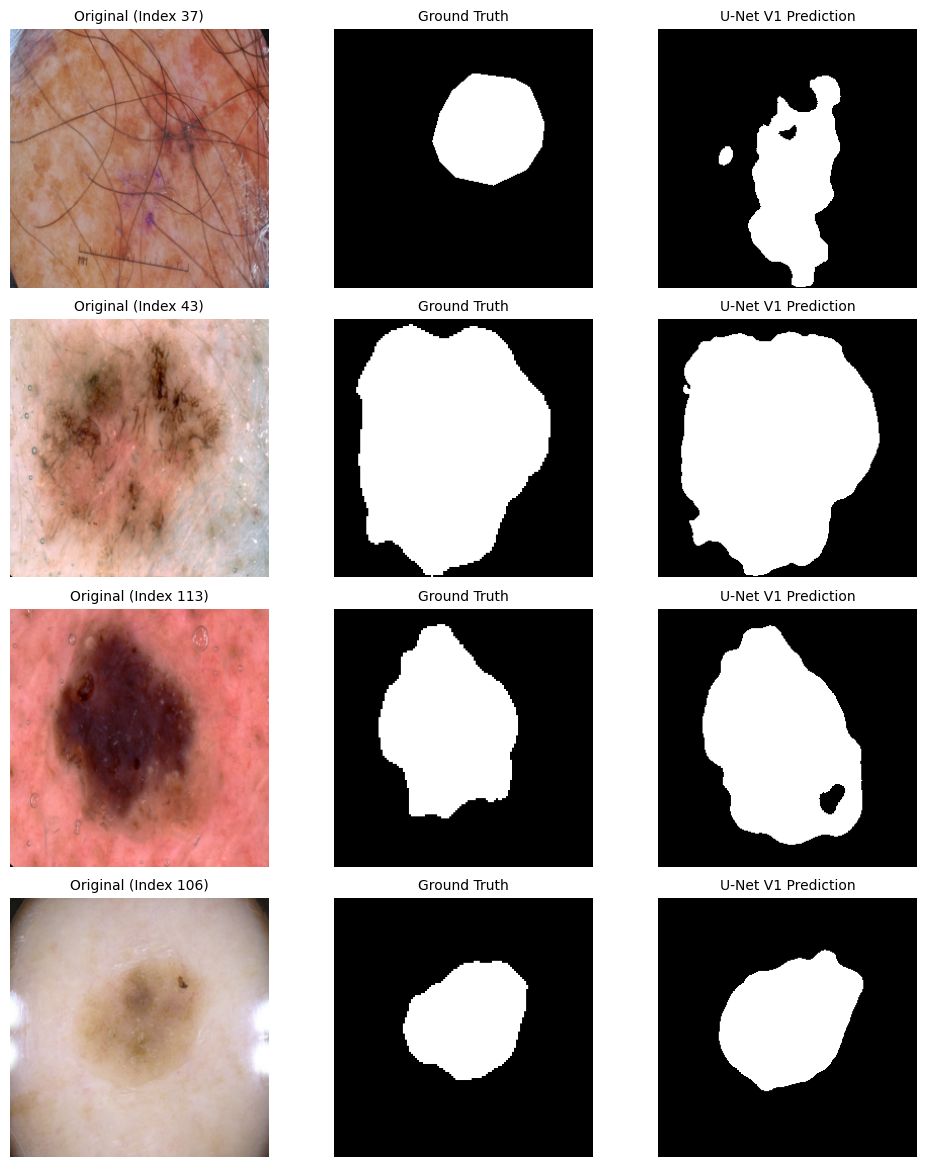

Random test indices: [37, 43, 113, 106]


In [152]:
import random
import torch
import matplotlib.pyplot as plt
import numpy as np

# Select 4 unique random test images
num_images = min(4, len(test_data))
random_indices = random.sample(range(len(test_data)), num_images)

base_v1.eval()

fig, axes = plt.subplots(
    num_images, 3,
    figsize=(10, 3 * num_images)
)

if num_images == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    for row, idx in enumerate(random_indices):

        image, ground_truth = test_data[idx]
        input_tensor = image.unsqueeze(0).to(device)

        # U-Net V1 prediction
        output_v1 = base_v1(input_tensor)

        pred_v1 = (
            torch.sigmoid(output_v1) > 0.5
        ).float().squeeze().cpu().numpy()

        gt = ground_truth.squeeze().cpu().numpy()
        img = image.permute(1, 2, 0).cpu().numpy()
        img = np.clip(img, 0, 1)

        # Original image
        axes[row, 0].imshow(img)
        axes[row, 0].set_title(
            f"Original (Index {idx})", fontsize=10
        )

        # Ground truth
        axes[row, 1].imshow(
            gt, cmap="gray", vmin=0, vmax=1
        )
        axes[row, 1].set_title(
            "Ground Truth", fontsize=10
        )

        # U-Net V1 prediction
        axes[row, 2].imshow(
            pred_v1, cmap="gray", vmin=0, vmax=1
        )
        axes[row, 2].set_title(
            "U-Net V1 Prediction", fontsize=10
        )

        for col in range(3):
            axes[row, col].axis("off")

plt.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.96,
    bottom=0.02,
    wspace=0.04,
    hspace=0.12
)

plt.show()

print("Random test indices:", random_indices)